Cell 1 — Imports

In [1]:
from pathlib import Path
import ast
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

Cell 2 — Paths

In [8]:
# =========================
# Path configuration
# =========================
USE_GRID = False

# LOCAL_ROOT = Path("/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/")
LOCAL_ROOT = Path("/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext")
# LOCAL_ROOT = Path("/home/arsalan/wsu_grid_rs_grp_mljet/")

GRID_ROOT  = Path("/rs/rs_grp_mljet/ml-jet-ext/")

BASE_ROOT = GRID_ROOT if USE_GRID else LOCAL_ROOT

# Unfolded single-image dataset
UNFOLDED_ROOT = BASE_ROOT / "pTHat50-250_eCM5020_c0005_pT90-110_R0p4"

# Existing agg500 mean dataset (for consistency checks only)
OLD_AGG500_ROOT = BASE_ROOT / "pTHat50-250_eCM5020_c0005_pT90-110_R0p4_agg500"

# New 5-moment dataset root
NEW_MOMENT_ROOT = BASE_ROOT / "pTHat50-250_eCM5020_c0005_pT90-110_R0p4_agg500_m1-5_normalized"
NEW_MOMENT_METADATA_DIR = NEW_MOMENT_ROOT / "metadata"

NEW_MOMENT_ROOT.mkdir(parents=True, exist_ok=True)
NEW_MOMENT_METADATA_DIR.mkdir(parents=True, exist_ok=True)

print("UNFOLDED_ROOT:", UNFOLDED_ROOT)
print("OLD_AGG500_ROOT:", OLD_AGG500_ROOT)
print("NEW_MOMENT_ROOT:", NEW_MOMENT_ROOT)
print("NEW_MOMENT_METADATA_DIR:", NEW_MOMENT_METADATA_DIR)

UNFOLDED_ROOT: /mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_c0005_pT90-110_R0p4
OLD_AGG500_ROOT: /mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_c0005_pT90-110_R0p4_agg500
NEW_MOMENT_ROOT: /mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_c0005_pT90-110_R0p4_agg500_m1-5_normalized
NEW_MOMENT_METADATA_DIR: /mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_c0005_pT90-110_R0p4_agg500_m1-5_normalized/metadata


Cell 3 — Read the 35 config CSVs from the new metadata folder

In [9]:
config_csvs = sorted(NEW_MOMENT_METADATA_DIR.glob("c0005_*_agg500_metadata.csv"))

print(f"Found {len(config_csvs)} config CSVs")
for p in config_csvs[:5]:
    print(" -", p.name)

Found 35 config CSVs
 - c0005_alpha0p20_q_1p0_agg500_metadata.csv
 - c0005_alpha0p20_q_1p5_agg500_metadata.csv
 - c0005_alpha0p20_q_2p0_agg500_metadata.csv
 - c0005_alpha0p20_q_2p5_agg500_metadata.csv
 - c0005_alpha0p20_q_3p0_agg500_metadata.csv


Cell 4 — Helper: parse source file paths

In [10]:
def parse_src_paths(value):
    """
    Supports:
      - Python list string
      - JSON list string
      - pipe-separated string
      - already a list
    """
    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    s = str(value).strip()

    if s.startswith("[") and s.endswith("]"):
        try:
            parsed = ast.literal_eval(s)
            if isinstance(parsed, list):
                return [str(x) for x in parsed]
        except Exception:
            try:
                parsed = json.loads(s)
                if isinstance(parsed, list):
                    return [str(x) for x in parsed]
            except Exception:
                pass

    if "|" in s:
        return [x.strip() for x in s.split("|") if x.strip()]

    return [s]

Cell 5 — Infer metadata column names

In [11]:
def find_column(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    raise KeyError(f"None of these columns found: {candidates}")


def infer_metadata_columns(df):
    file_col = find_column(df, ["file_paths", "src_file_paths", "source_file_paths", "member_file_paths"])
    agg_col  = find_column(df, ["agg_file_path", "file_path", "agg_path"])

    alpha_col = find_column(df, ["alpha", "alpha_s", "alpha_value"])
    q0_col    = find_column(df, ["q0", "Q0", "q_0"])
    # eloss_col = find_column(df, ["energy_loss", "eloss", "energy_loss_module"])

    # sample_id_col = None
    # for c in ["agg_id", "sample_id", "group_id", "id"]:
    #     if c in df.columns:
    #         sample_id_col = c
    #         break

    return {
        "file_col": file_col,
        "agg_col": agg_col,
        "alpha_col": alpha_col,
        "q0_col": q0_col,
        # "eloss_col": eloss_col,
        # "sample_id_col": sample_id_col,
    }

Cell 6 — Inspect one config CSV

In [12]:
test_csv = config_csvs[0]
df_test = pd.read_csv(test_csv)

print("Testing:", test_csv.name)
print("Shape:", df_test.shape)
display(df_test.head())

colmap = infer_metadata_columns(df_test)
print(colmap)

Testing: c0005_alpha0p20_q_1p0_agg500_metadata.csv
Shape: (920, 5)


,agg_file_path,alpha,config,q0,source_file_paths
0,c0005_alpha0p20_q_1p0/agg500_event_0000000.npy,0.2,c0005_alpha0p20_q_1p0,1.0,c0005_alpha0p20_q_1p0_unfolded/seed_142/event_...
1,c0005_alpha0p20_q_1p0/agg500_event_0000000.npy,0.2,c0005_alpha0p20_q_1p0,1.0,c0005_alpha0p20_q_1p0_unfolded/seed_142/event_...
2,c0005_alpha0p20_q_1p0/agg500_event_0000001.npy,0.2,c0005_alpha0p20_q_1p0,1.0,c0005_alpha0p20_q_1p0_unfolded/seed_129/event_...
3,c0005_alpha0p20_q_1p0/agg500_event_0000001.npy,0.2,c0005_alpha0p20_q_1p0,1.0,c0005_alpha0p20_q_1p0_unfolded/seed_129/event_...
4,c0005_alpha0p20_q_1p0/agg500_event_0000002.npy,0.2,c0005_alpha0p20_q_1p0,1.0,c0005_alpha0p20_q_1p0_unfolded/seed_136/event_...


{'file_col': 'source_file_paths', 'agg_col': 'agg_file_path', 'alpha_col': 'alpha', 'q0_col': 'q0'}


Cell 7 — Helper: load one unfolded jet image

In [7]:
def load_single_jet_image(rel_path):
    rel_path = str(rel_path).strip()
    img_path = UNFOLDED_ROOT / rel_path

    if not img_path.exists():
        raise FileNotFoundError(f"Missing source image: {img_path}")

    arr = np.load(img_path).astype(np.float32)
    return arr

Cell 8 — Compute moments 1–5

In [8]:
def compute_moments_1_to_5(stack):
    """
    stack: [N, 32, 32]
    returns: [5, 32, 32]
    """
    stack = np.asarray(stack, dtype=np.float32)
    assert stack.ndim == 3, f"Expected [N,H,W], got {stack.shape}"

    m1 = stack.mean(axis=0)
    centered = stack - m1

    m2 = (centered ** 2).mean(axis=0)
    m3 = (centered ** 3).mean(axis=0)
    m4 = (centered ** 4).mean(axis=0)
    m5 = (centered ** 5).mean(axis=0)

    return np.stack([m1, m2, m3, m4, m5], axis=0).astype(np.float32)

Cell 9 — Build the new output relative path
This preserves the same config-based folder style.

In [9]:
def build_new_relpath_from_old_agg(old_agg_relpath: str):
    """
    Reuse the same relative structure as agg500 mean dataset,
    but save the new 5-channel tensor under the new root.
    """
    return str(old_agg_relpath)

Cell 10 — Smoke test on one aggregated sample

In [10]:

row = df_test.iloc[0]

src_paths = parse_src_paths(row[colmap["file_col"]])
print("Number of source paths:", len(src_paths))
print("First 3 paths:")
for p in src_paths[:3]:
    print("  ", p)

stack = np.stack([load_single_jet_image(p) for p in src_paths], axis=0)
print("Stack shape:", stack.shape)

moments = compute_moments_1_to_5(stack)
print("Moments shape:", moments.shape)

for i in range(5):
    print(
        f"m{i+1}: "
        f"min={moments[i].min():.6f}, "
        f"max={moments[i].max():.6f}, "
        f"mean={moments[i].mean():.6f}, "
        f"std={moments[i].std():.6f}"
    )



Number of source paths: 500
First 3 paths:
   c0005_alpha0p20_q_1p0_unfolded/seed_142/event_0000220.npy
   c0005_alpha0p20_q_1p0_unfolded/seed_002/event_0000400.npy
   c0005_alpha0p20_q_1p0_unfolded/seed_165/event_0000415.npy
Stack shape: (500, 32, 32)
Moments shape: (5, 32, 32)
m1: min=0.000000, max=14.316760, mean=0.097671, std=0.877401
m2: min=0.000000, max=345.205536, mean=1.655504, std=20.983768
m3: min=0.000000, max=10472.893555, mean=44.819202, std=630.380676
m4: min=0.000000, max=622215.312500, mean=2480.460449, std=37355.269531
m5: min=0.000000, max=34974004.000000, mean=133355.031250, std=2055359.125000


Cell 12 — Visualize one sample

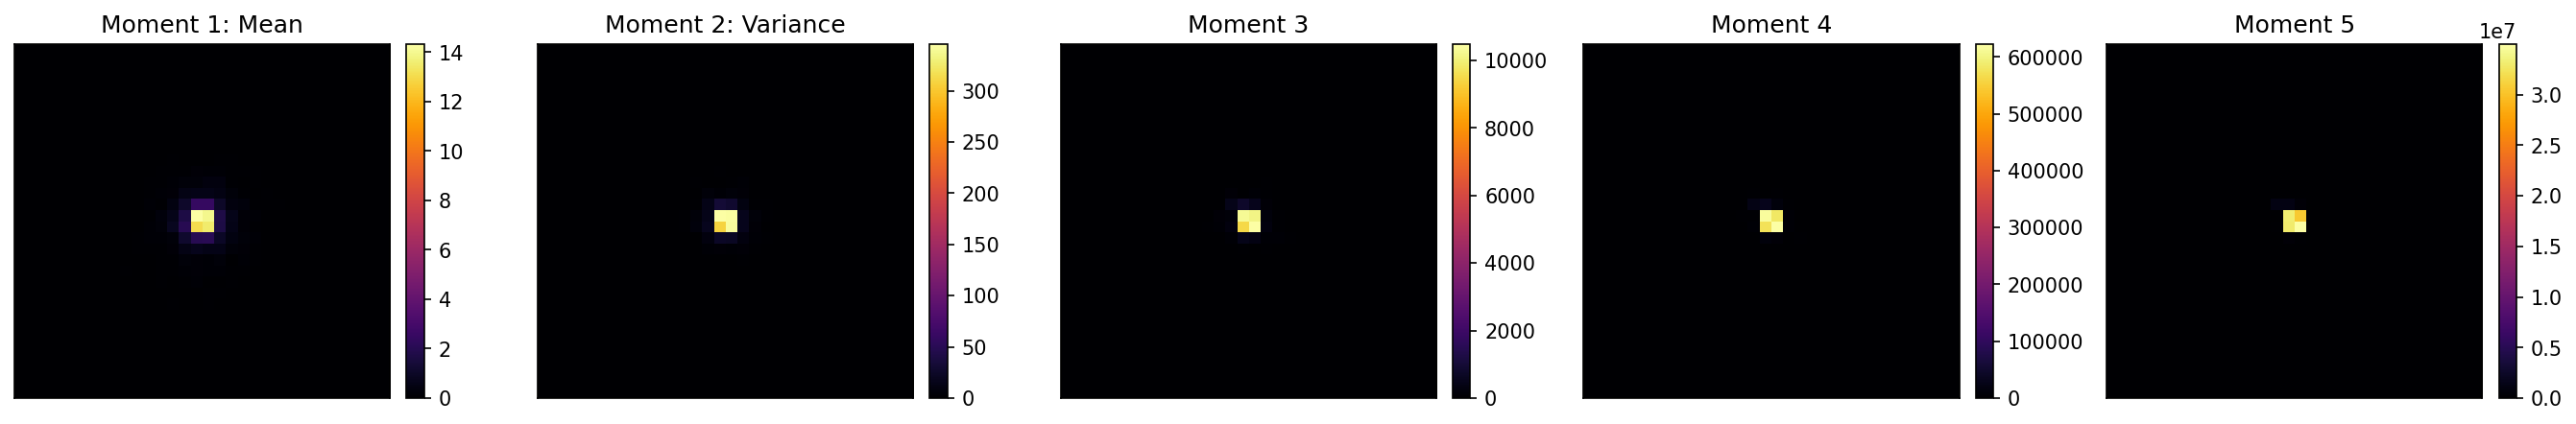

In [12]:

titles = [
    "Moment 1: Mean",
    "Moment 2: Variance",
    "Moment 3",
    "Moment 4",
    "Moment 5"
]

fig, axes = plt.subplots(1, 5, figsize=(18, 3), dpi=150)

for i in range(5):
    ax = axes[i]
    im = ax.imshow(moments[i].T, origin="lower", cmap="inferno", aspect="auto")
    ax.set_title(titles[i])
    ax.set_xticks([])
    ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()



In [13]:
import math


def log_normalize_image(img, epsilon=1e-8, img_max=1.0):
    """
    Log normalize nonnegative image to [0, 1].
    """
    I = np.asarray(img, dtype=np.float32)

    if img_max <= 0:
        return np.zeros_like(I, dtype=np.float32)

    num = np.log(I + epsilon) - math.log(epsilon)
    den = math.log(img_max + epsilon) - math.log(epsilon)

    if den <= 0:
        return np.zeros_like(I, dtype=np.float32)

    I_log = num / den
    return np.clip(I_log, 0.0, 1.0).astype(np.float32)


def signed_log_normalize_image(img, epsilon=1e-8, img_abs_max=1.0):
    """
    Signed log normalize image to [-1, 1].
    Suitable for odd central moments that may be negative.
    """
    I = np.asarray(img, dtype=np.float32)

    if img_abs_max <= 0:
        return np.zeros_like(I, dtype=np.float32)

    mag = np.abs(I)
    num = np.log(mag + epsilon) - math.log(epsilon)
    den = math.log(img_abs_max + epsilon) - math.log(epsilon)

    if den <= 0:
        return np.zeros_like(I, dtype=np.float32)

    I_log = num / den
    I_signed = np.sign(I) * np.clip(I_log, 0.0, 1.0)
    return I_signed.astype(np.float32)


def normalize_moments_1_to_5(moments, epsilon=1e-8):
    """
    moments: [5, H, W]
    Returns normalized moments:
      m1, m2, m4 -> [0, 1]
      m3, m5     -> [-1, 1]
    """
    moments = np.asarray(moments, dtype=np.float32)
    assert moments.shape[0] == 5, f"Expected 5 channels, got {moments.shape}"

    m1_max = 110.0
    m2_max = 110.0 ** 2
    m3_abs_max = 110.0 ** 3
    m4_max = 110.0 ** 4
    m5_abs_max = 110.0 ** 5

    out = np.stack([
        log_normalize_image(moments[0], epsilon=epsilon, img_max=m1_max),
        log_normalize_image(moments[1], epsilon=epsilon, img_max=m2_max),
        signed_log_normalize_image(moments[2], epsilon=epsilon, img_abs_max=m3_abs_max),
        log_normalize_image(moments[3], epsilon=epsilon, img_max=m4_max),
        signed_log_normalize_image(moments[4], epsilon=epsilon, img_abs_max=m5_abs_max),
    ], axis=0).astype(np.float32)

    return out


In [14]:

moments = normalize_moments_1_to_5(moments, epsilon=1e-8)
print("Log-normalized moments shape:", moments.shape)
for i in range(5):
    print(
        f"m{i+1}_log: "
        f"min={moments[i].min():.6f}, "
        f"max={moments[i].max():.6f}, "
        f"mean={moments[i].mean():.6f}, "
        f"std={moments[i].std():.6f}"
    )


Log-normalized moments shape: (5, 32, 32)
m1_log: min=0.000000, max=0.911810, mean=0.327168, std=0.306689
m2_log: min=0.000000, max=0.872156, mean=0.278995, std=0.269314
m3_log: min=0.000000, max=0.851028, mean=0.247717, std=0.248864
m4_log: min=0.000000, max=0.853291, mean=0.226015, std=0.237178
m5_log: min=0.000000, max=0.853725, mean=0.210256, std=0.229395


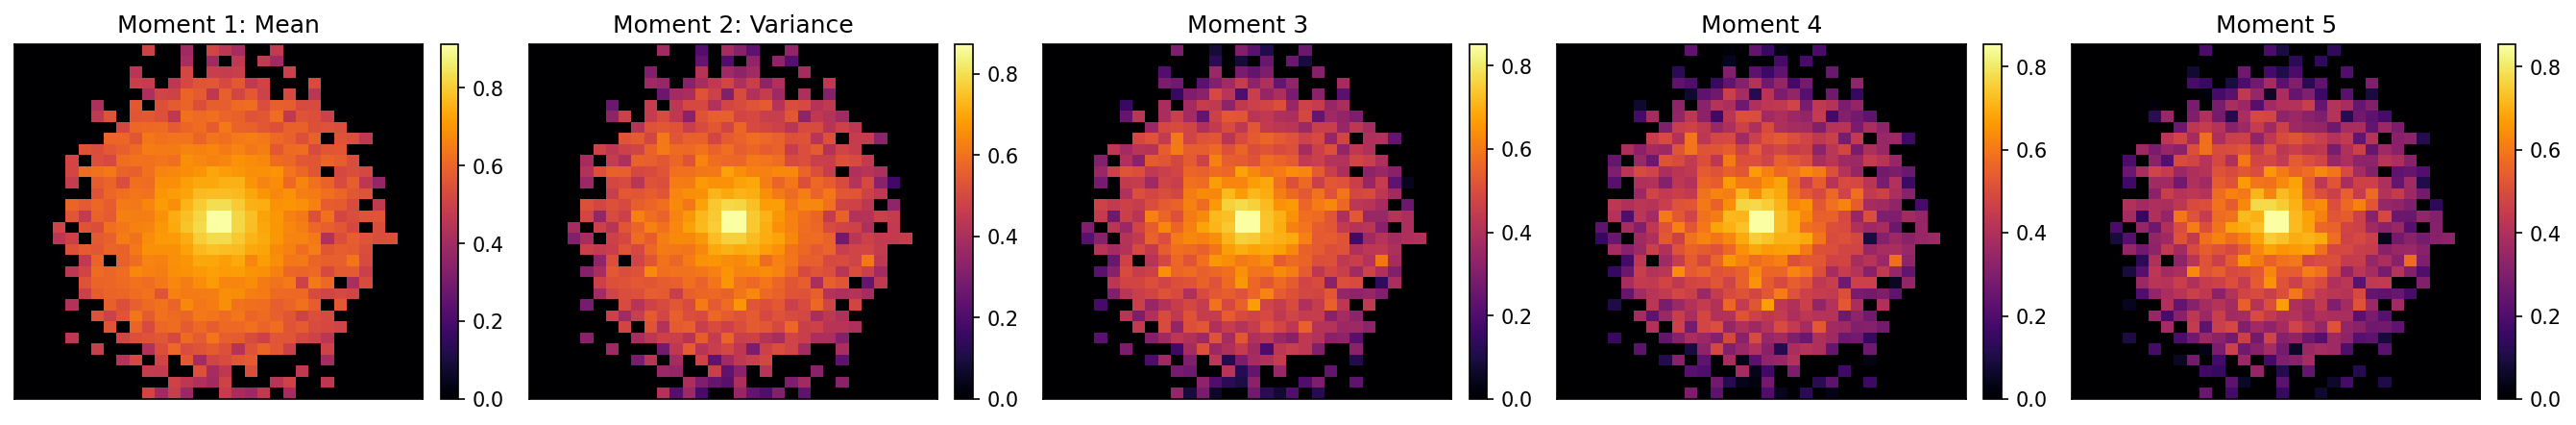

In [15]:
        
titles = [
    "Moment 1: Mean",
    "Moment 2: Variance",
    "Moment 3",
    "Moment 4",
    "Moment 5"
]

fig, axes = plt.subplots(1, 5, figsize=(18, 3), dpi=150)

for i in range(5):
    ax = axes[i]
    im = ax.imshow(moments[i].T, origin="lower", cmap="inferno", aspect="auto")
    ax.set_title(titles[i])
    ax.set_xticks([])
    ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()



Cell 13 — Save one sample in the new format

In [18]:

new_rel = build_new_relpath_from_old_agg(row[colmap["agg_col"]])
new_abs = NEW_MOMENT_ROOT / new_rel
new_abs.parent.mkdir(parents=True, exist_ok=True)

np.save(new_abs, moments.astype(np.float32))

print("Saved:", new_abs)
print("Saved shape:", np.load(new_abs).shape)



Saved: /home/arsalan/wsu_grid_rs_grp_mljet/pTHat50-250_eCM5020_c0005_pT90-110_R0p4_agg500_m1-5/c0005_alpha0p20_q_1p0/agg500_event_0000000.npy
Saved shape: (5, 32, 32)


Cell 14 — Process one config CSV

In [ ]:
def process_one_config_csv(csv_path, overwrite=False, verbose=True):
    df = pd.read_csv(csv_path)
    colmap = infer_metadata_columns(df)

    out_rows = []

    if verbose:
        print(f"[INFO] Processing {csv_path.name} with {len(df)} rows")

    for _, row in tqdm(df.iterrows(), total=len(df), desc=csv_path.stem):
        src_paths = parse_src_paths(row[colmap["file_col"]])

        if len(src_paths) != 500:
            raise ValueError(
                f"{csv_path.name}: Expected 500 source images, got {len(src_paths)}"
            )

        stack = np.stack([load_single_jet_image(p) for p in src_paths], axis=0)
        moments = compute_moments_1_to_5(stack)
        moments_log = normalize_moments_1_to_5(moments, epsilon=1e-8)
        old_agg_rel = row[colmap["agg_col"]]
        new_rel = build_new_relpath_from_old_agg(old_agg_rel)
        new_abs = NEW_MOMENT_ROOT / new_rel
        new_abs.parent.mkdir(parents=True, exist_ok=True)

        if overwrite or (not new_abs.exists()):
            np.save(new_abs, moments_log.astype(np.float32))

        out_row = row.to_dict()
        out_row[colmap["agg_col"]] = new_rel
        out_rows.append(out_row)

    out_df = pd.DataFrame(out_rows)

    out_csv = NEW_MOMENT_METADATA_DIR / csv_path.name
    out_df.to_csv(out_csv, index=False)

    if verbose:
        print(f"[INFO] Saved updated metadata to: {out_csv}")
        print(f"[INFO] Wrote {len(out_df)} rows")

    return out_df

Cell 15 — Smoke test on one full config

In [13]:
smoke_df = process_one_config_csv(config_csvs[0], overwrite=False, verbose=True)
display(smoke_df.head())

NameError: name 'process_one_config_csv' is not defined

Cell 16 — Verify one saved file from the smoke run

In [18]:
def verify_return_moments(config_index,image_index=500):
    smoke_csv = NEW_MOMENT_METADATA_DIR / config_csvs[config_index].name
    smoke_df = pd.read_csv(smoke_csv)
    smoke_colmap = infer_metadata_columns(smoke_df)

    sample_rel = smoke_df.iloc[image_index][smoke_colmap["agg_col"]]
    sample_abs = NEW_MOMENT_ROOT / sample_rel
    sample_arr = np.load(sample_abs)

    print("Sample file:", sample_abs)
    print("Shape:", sample_arr.shape)

    for i in range(5):
        print(
            f"m{i+1}: min={sample_arr[i].min():.6f}, "
            f"max={sample_arr[i].max():.6f}, "
            f"mean={sample_arr[i].mean():.6f}, "
            f"std={sample_arr[i].std():.6f}"
        )
    return sample_arr

config_sample_arr = []
for idx in range(len(config_csvs)):
    print(f"Verifying config {idx}: {config_csvs[idx].name}")
    sample_arr = verify_return_moments(config_index=idx, image_index=500)
    config_sample_arr.append(sample_arr)

Verifying config 0: c0005_alpha0p20_q_1p0_agg500_metadata.csv
Sample file: /mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_c0005_pT90-110_R0p4_agg500_m1-5_normalized/c0005_alpha0p20_q_1p0/agg500_event_0000250.npy
Shape: (5, 32, 32)
m1: min=0.000000, max=0.914107, mean=0.320929, std=0.306118
m2: min=0.000000, max=0.874238, mean=0.273316, std=0.268335
m3: min=0.000000, max=0.853996, mean=0.242307, std=0.247520
m4: min=0.000000, max=0.858078, mean=0.220602, std=0.235668
m5: min=0.000000, max=0.859053, mean=0.204638, std=0.227988
Verifying config 1: c0005_alpha0p20_q_1p5_agg500_metadata.csv
Sample file: /mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_c0005_pT90-110_R0p4_agg500_m1-5_normalized/c0005_alpha0p20_q_1p5/agg500_event_0000229.npy
Shape: (5, 32, 32)
m1: min=0.000000, max=0.912379, mean=0.317504, std=0.308541
m2: min=0.000000, max=0.870784, mean=0.272113, std=0.270904
m3: min=0.000000, max=0.847306, mean=0.242768, std=0.249846
m4

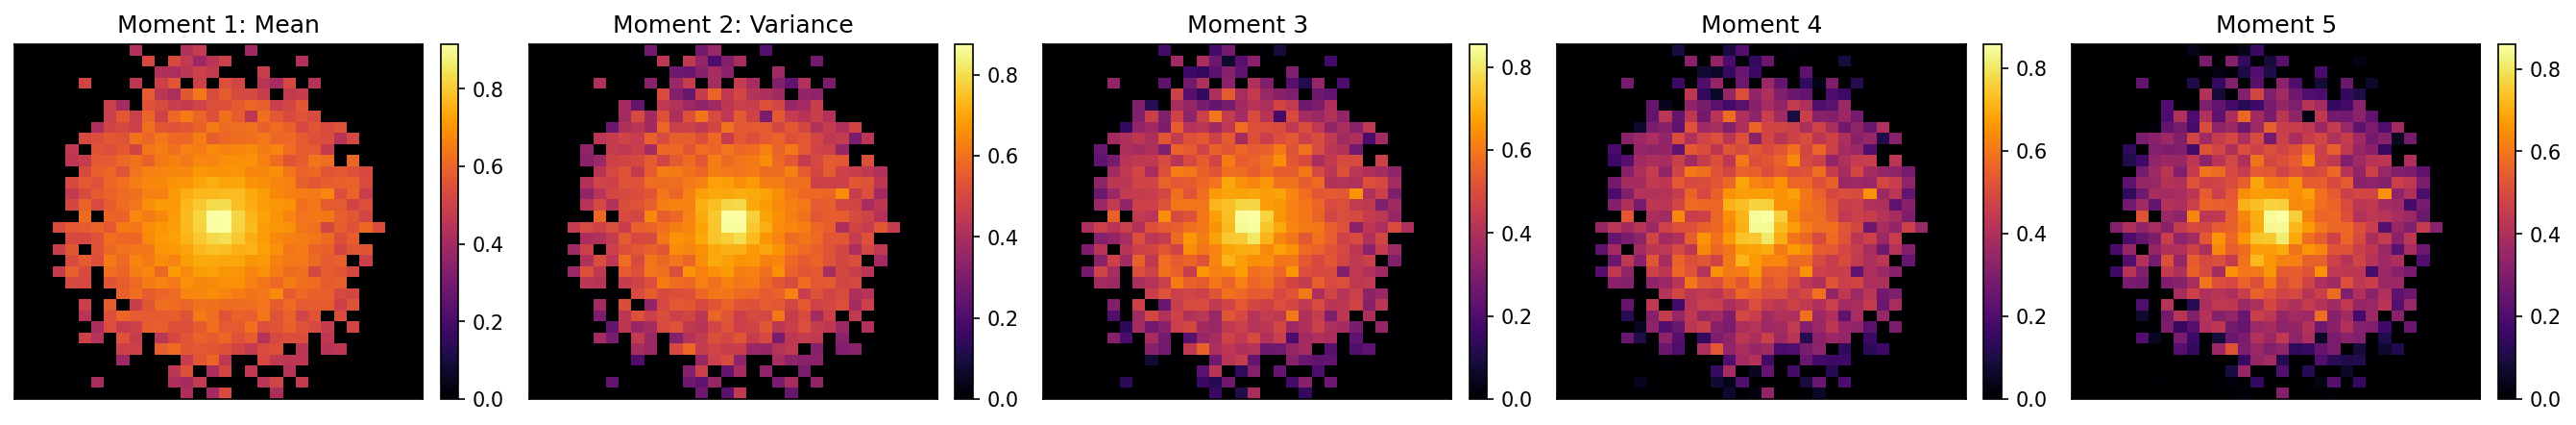

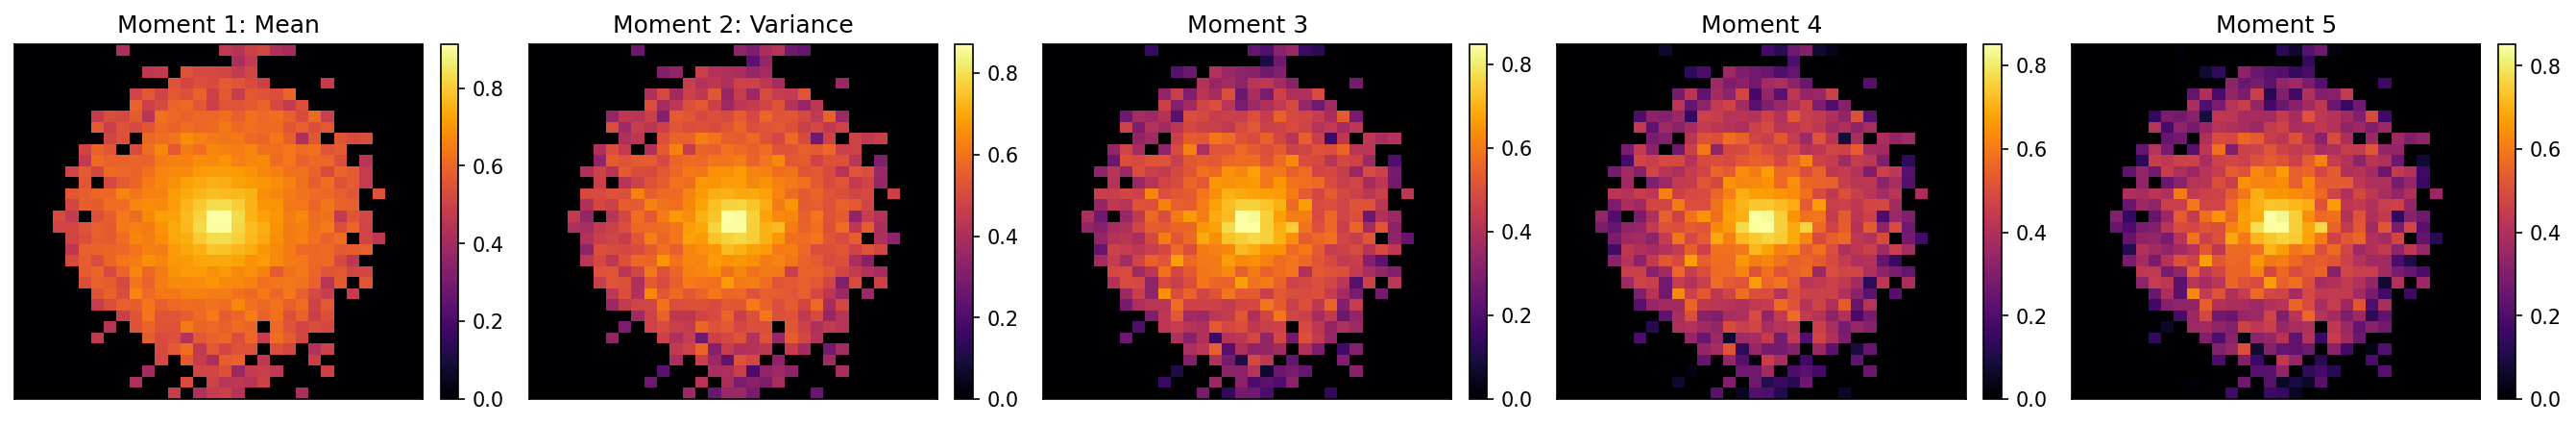

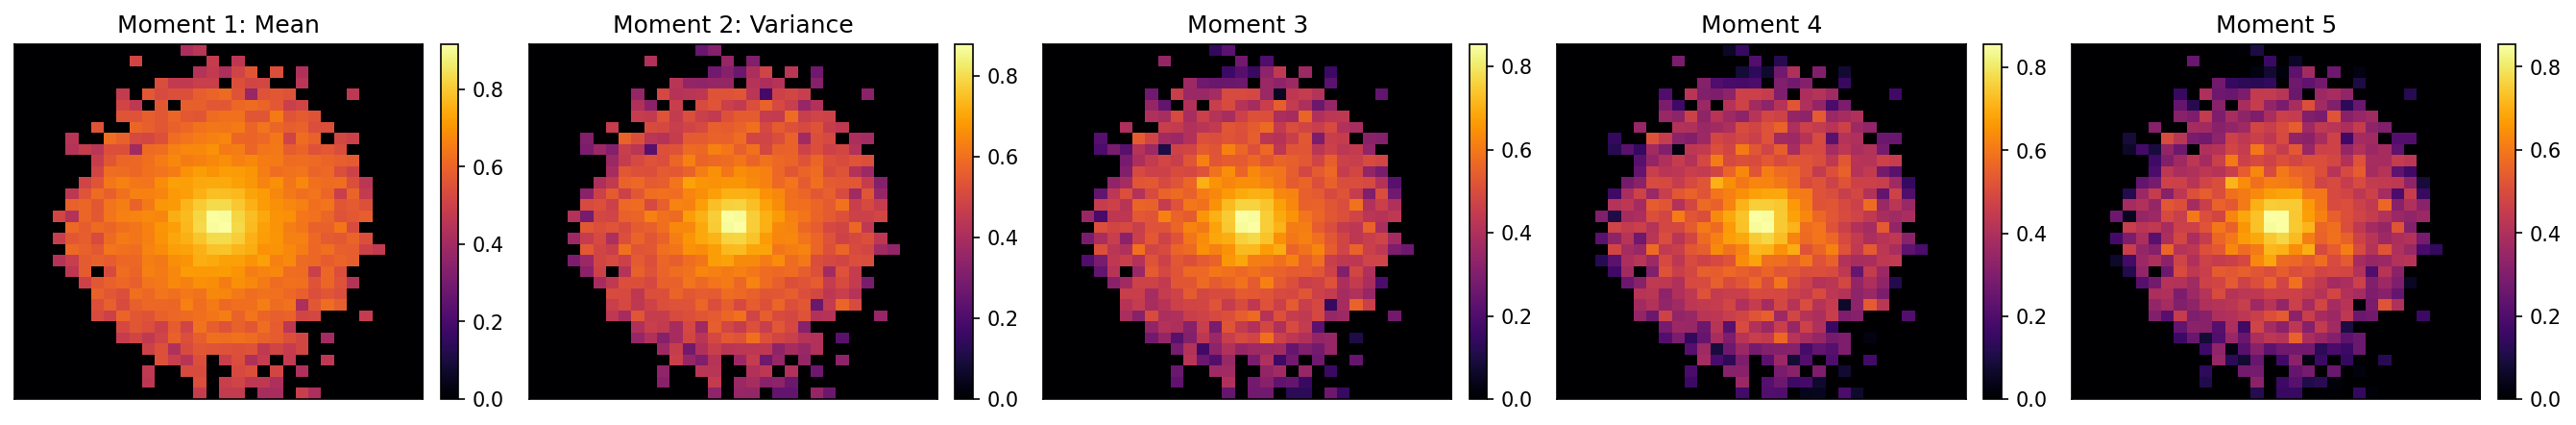

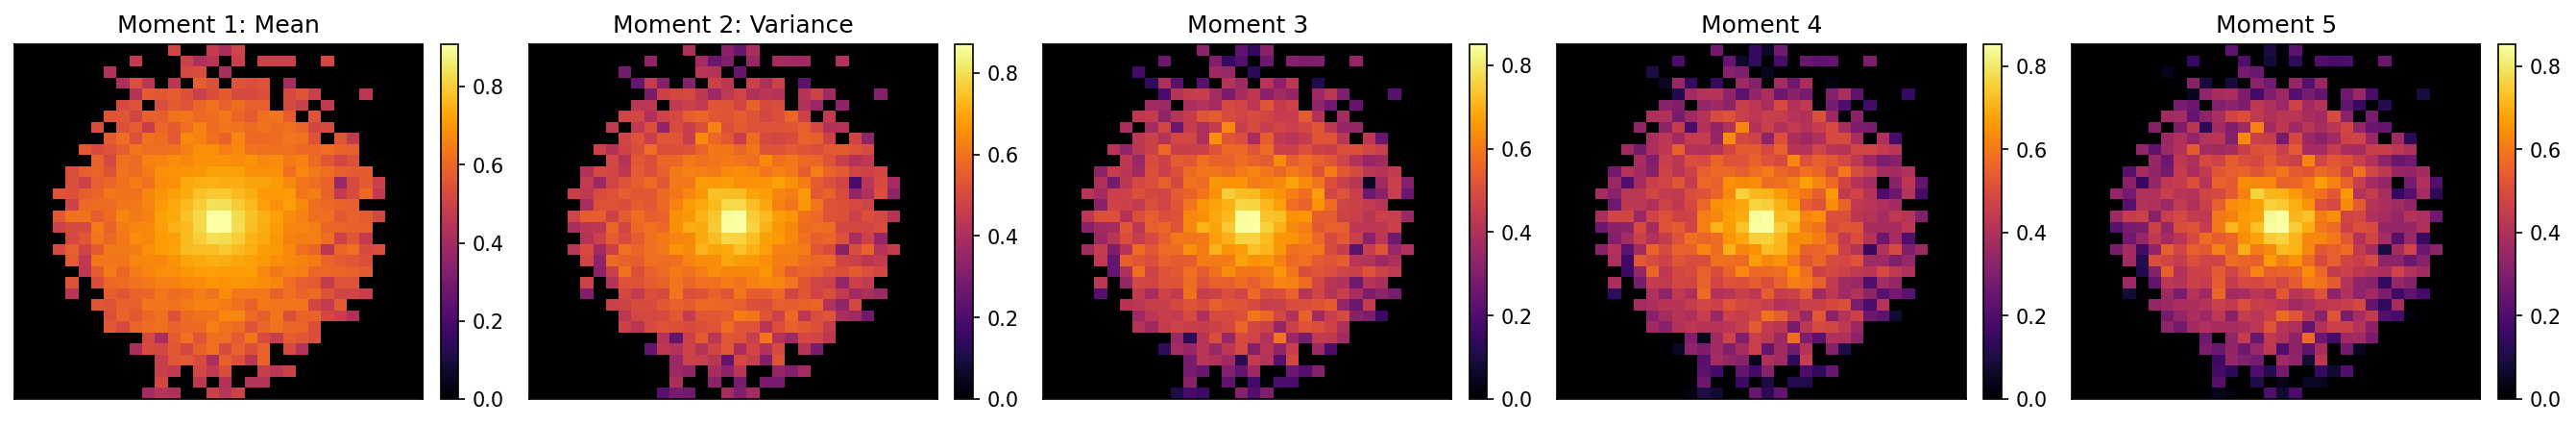

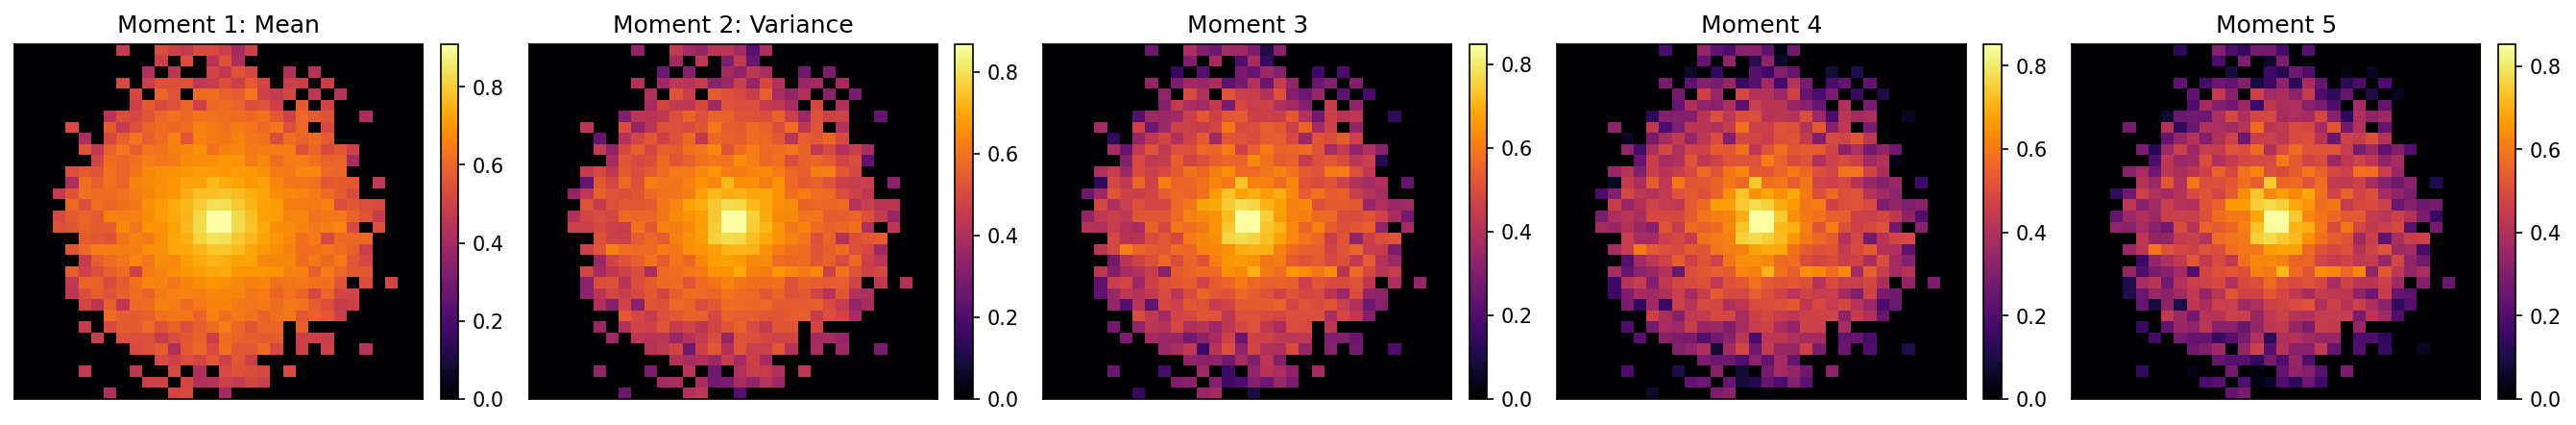

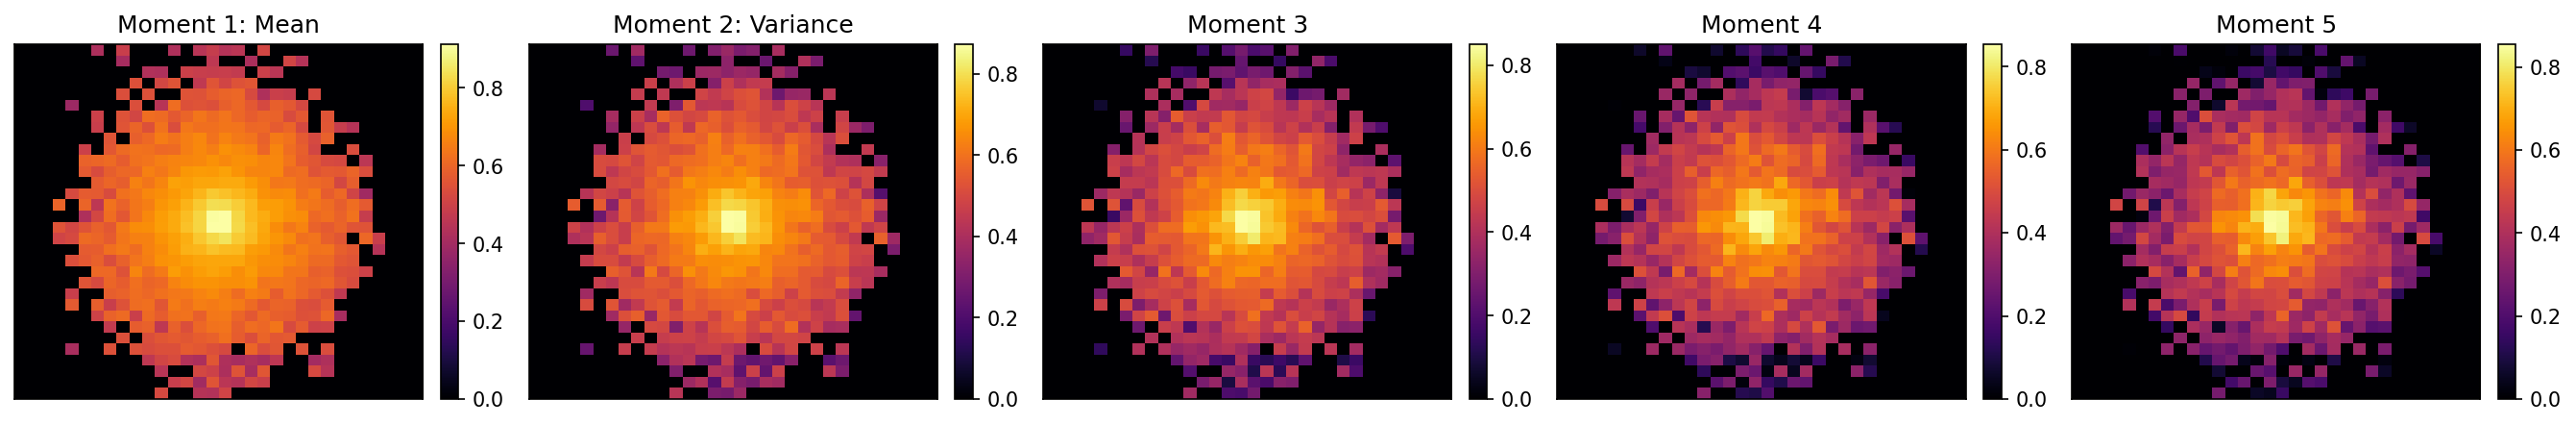

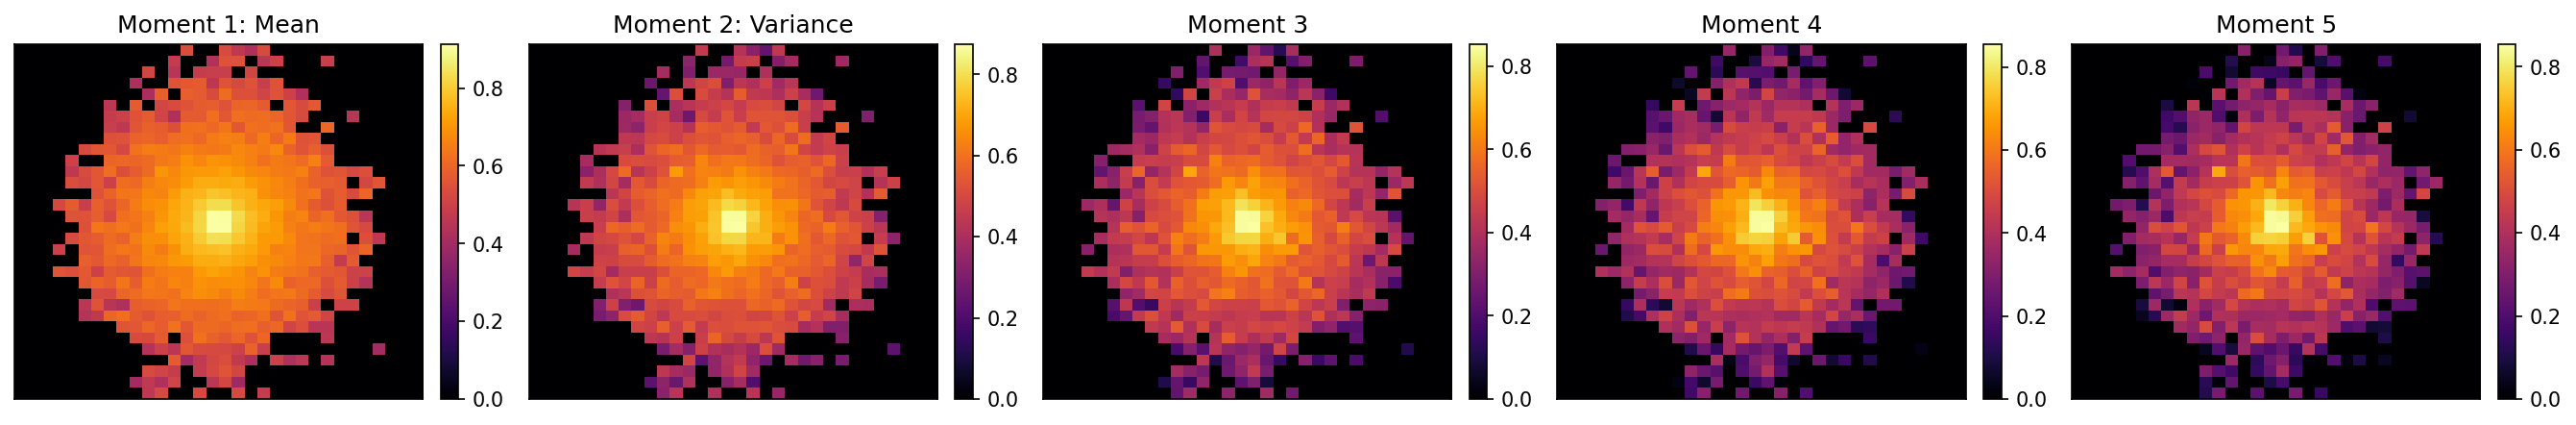

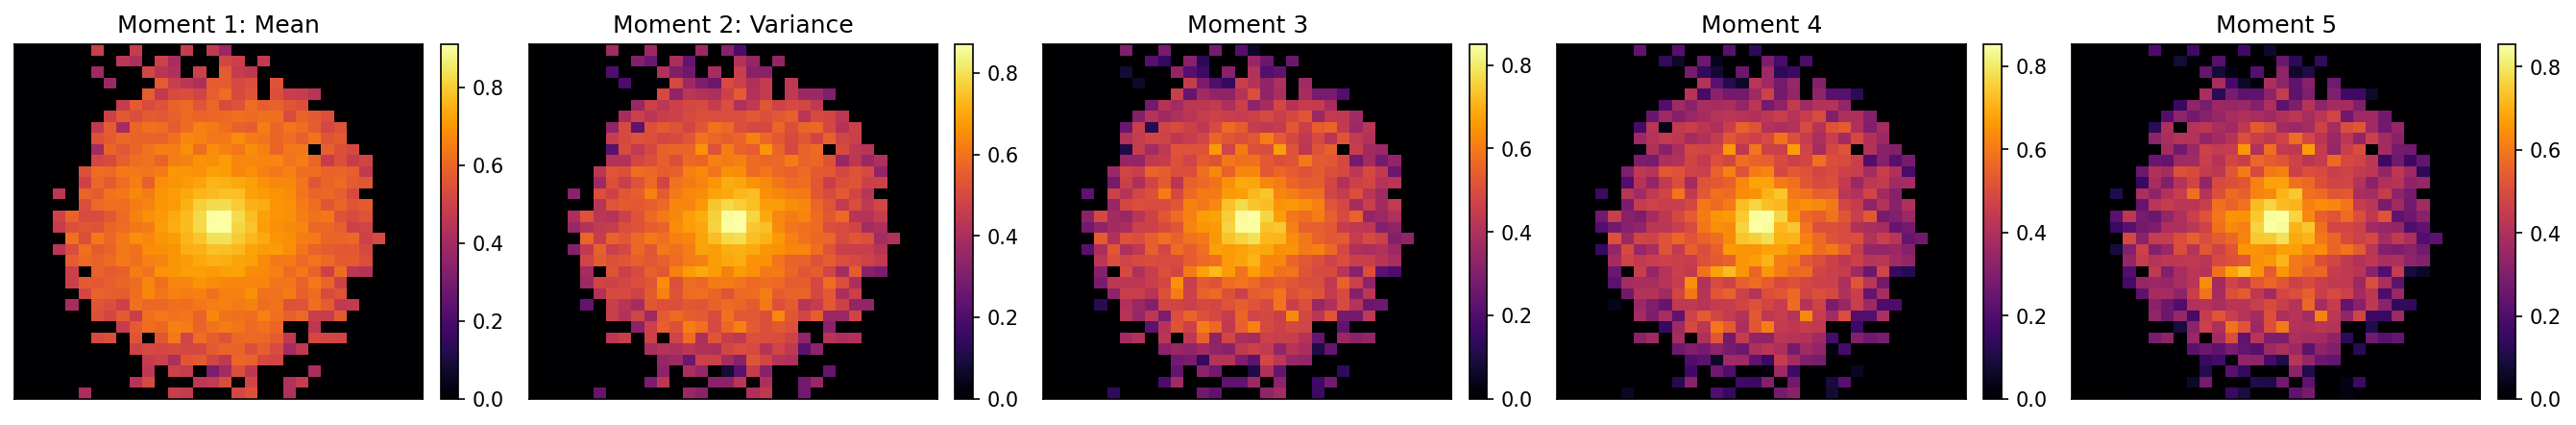

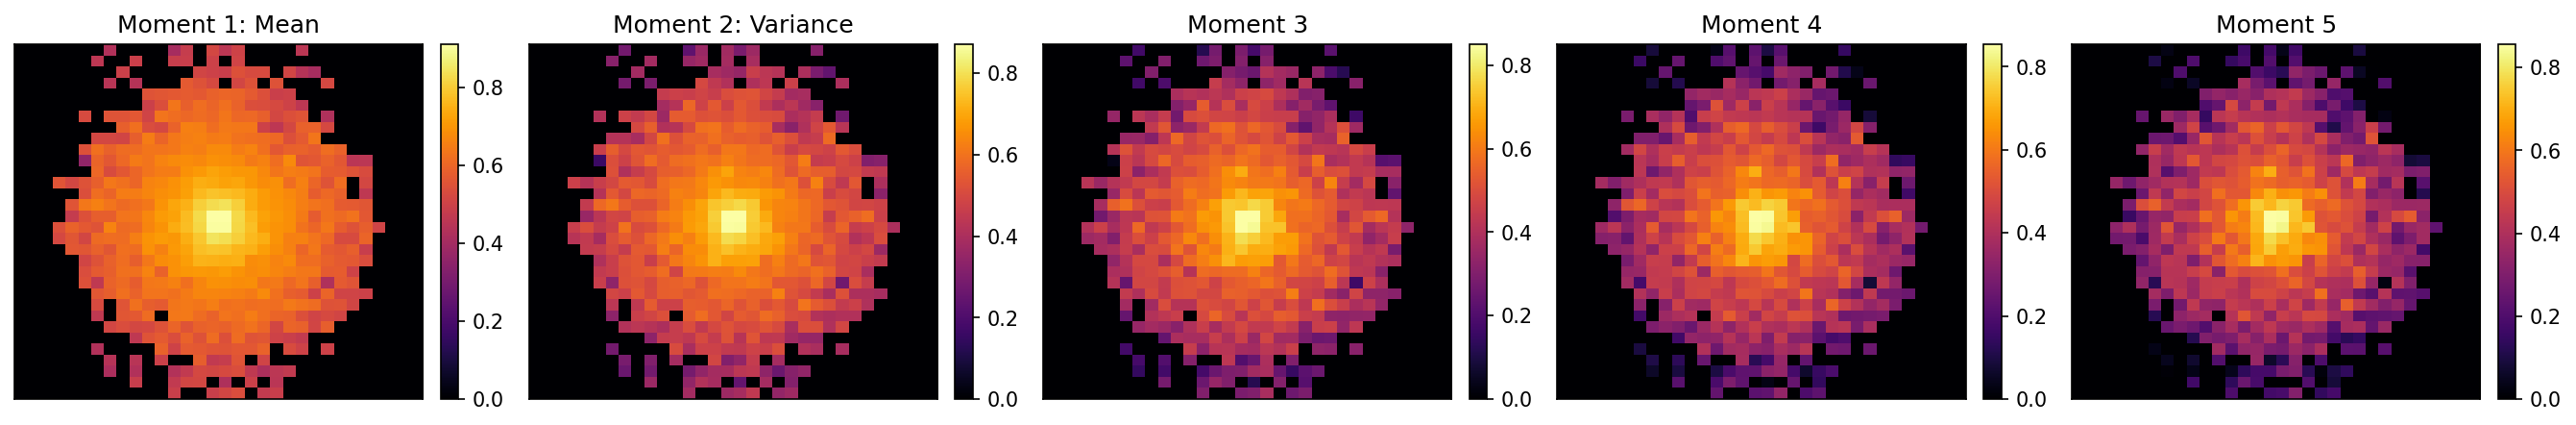

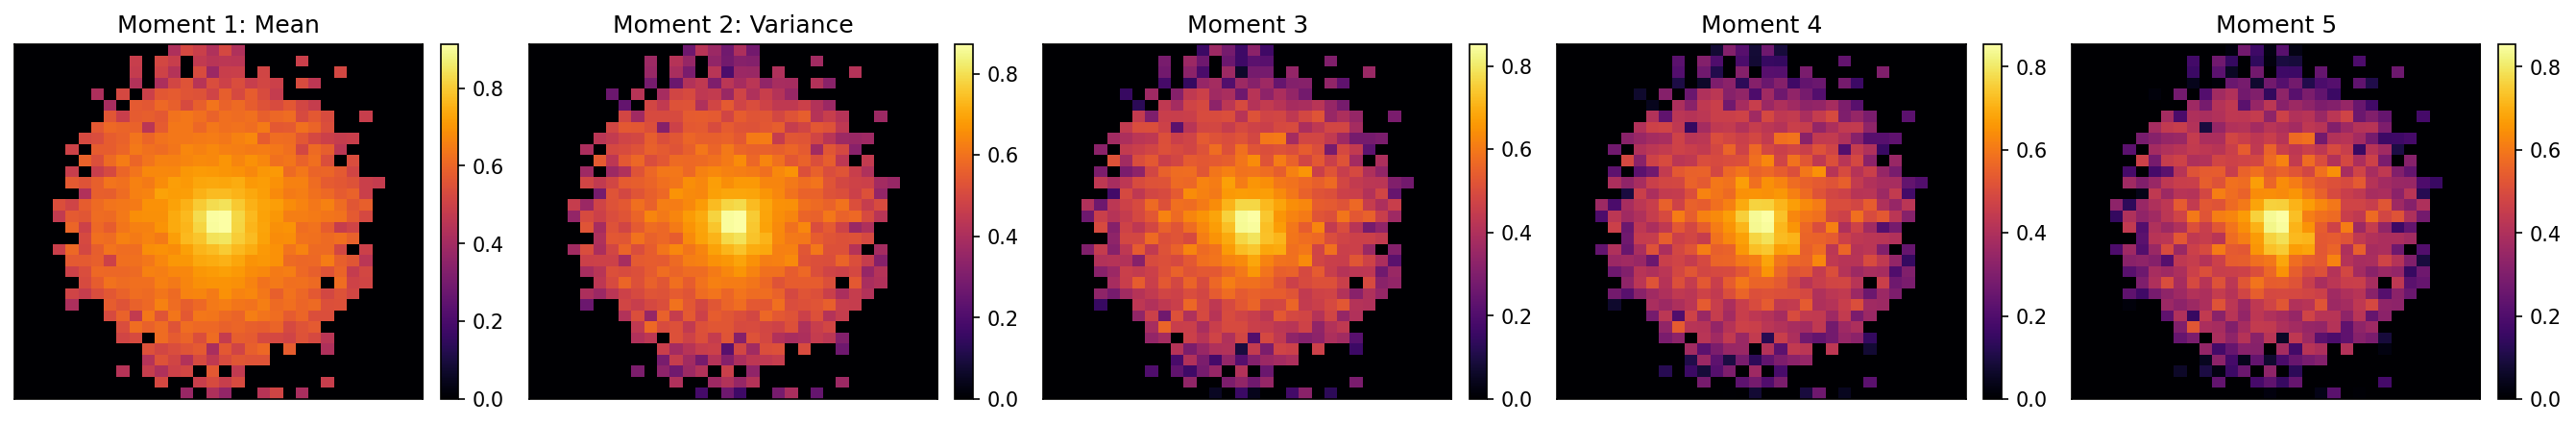

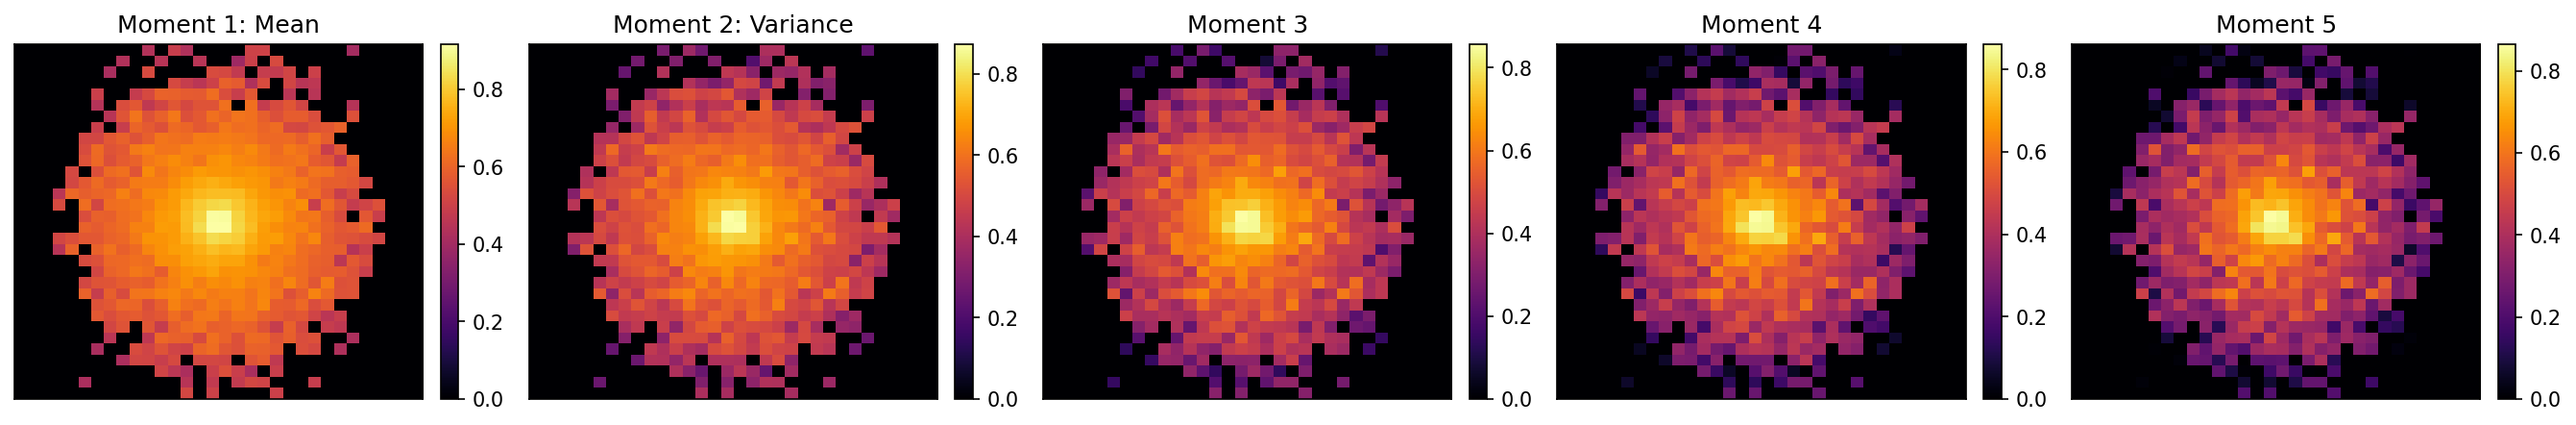

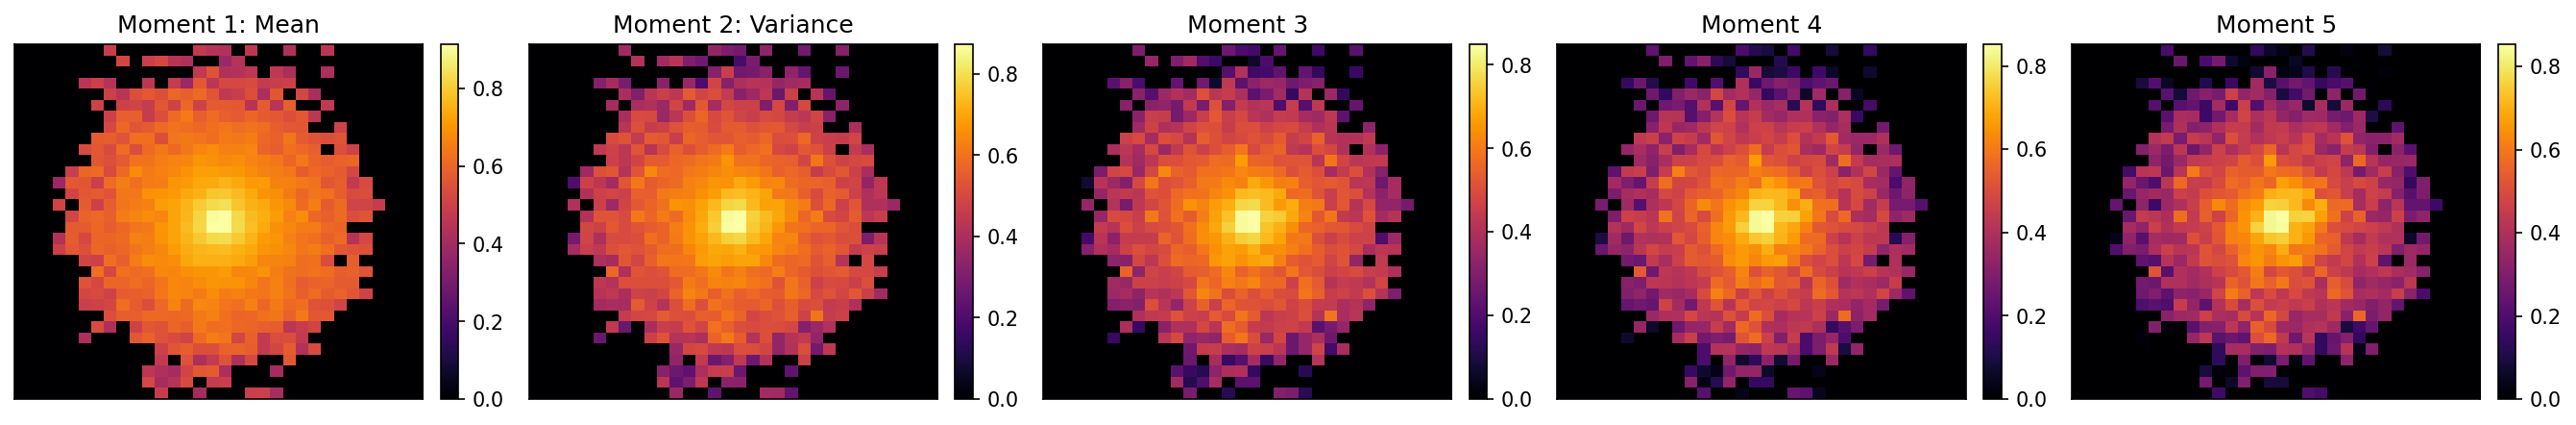

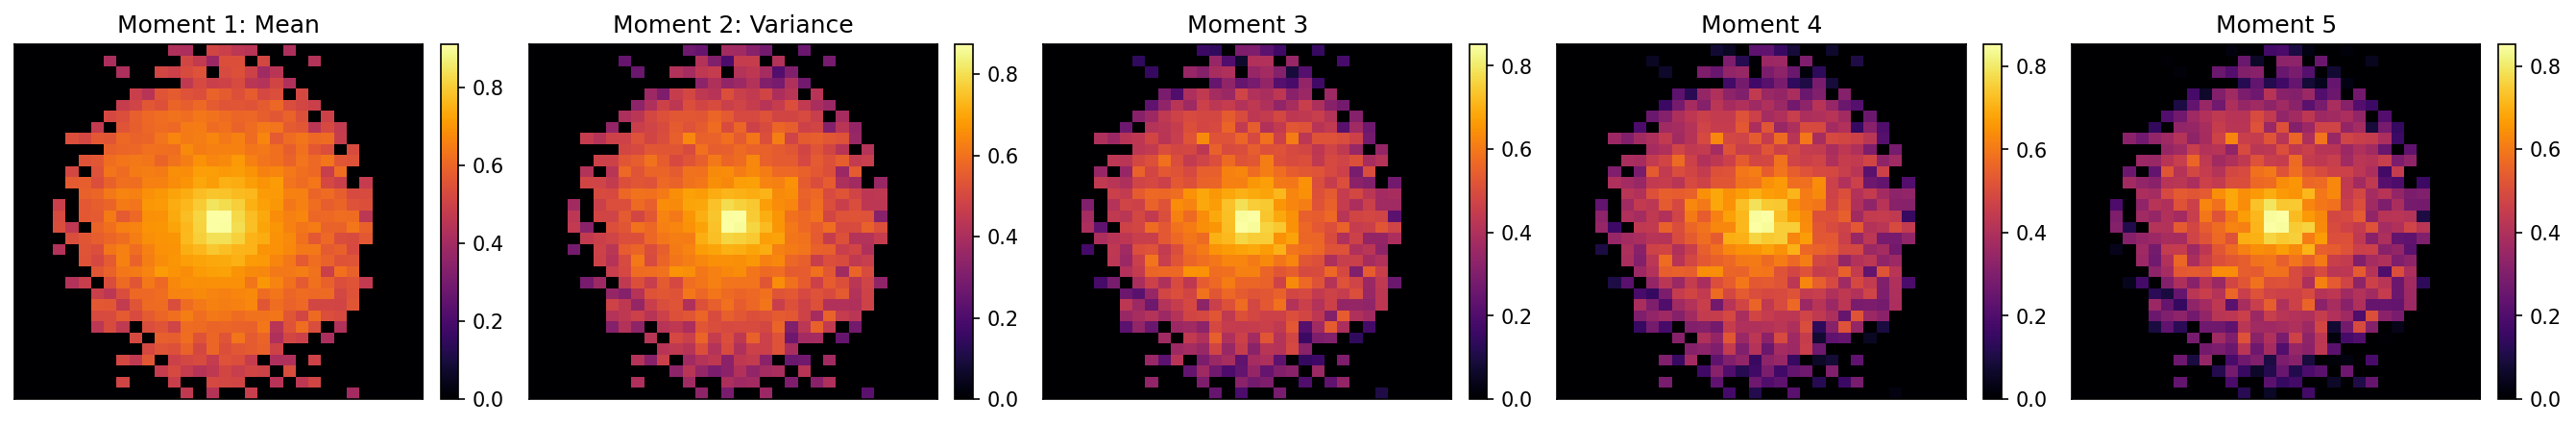

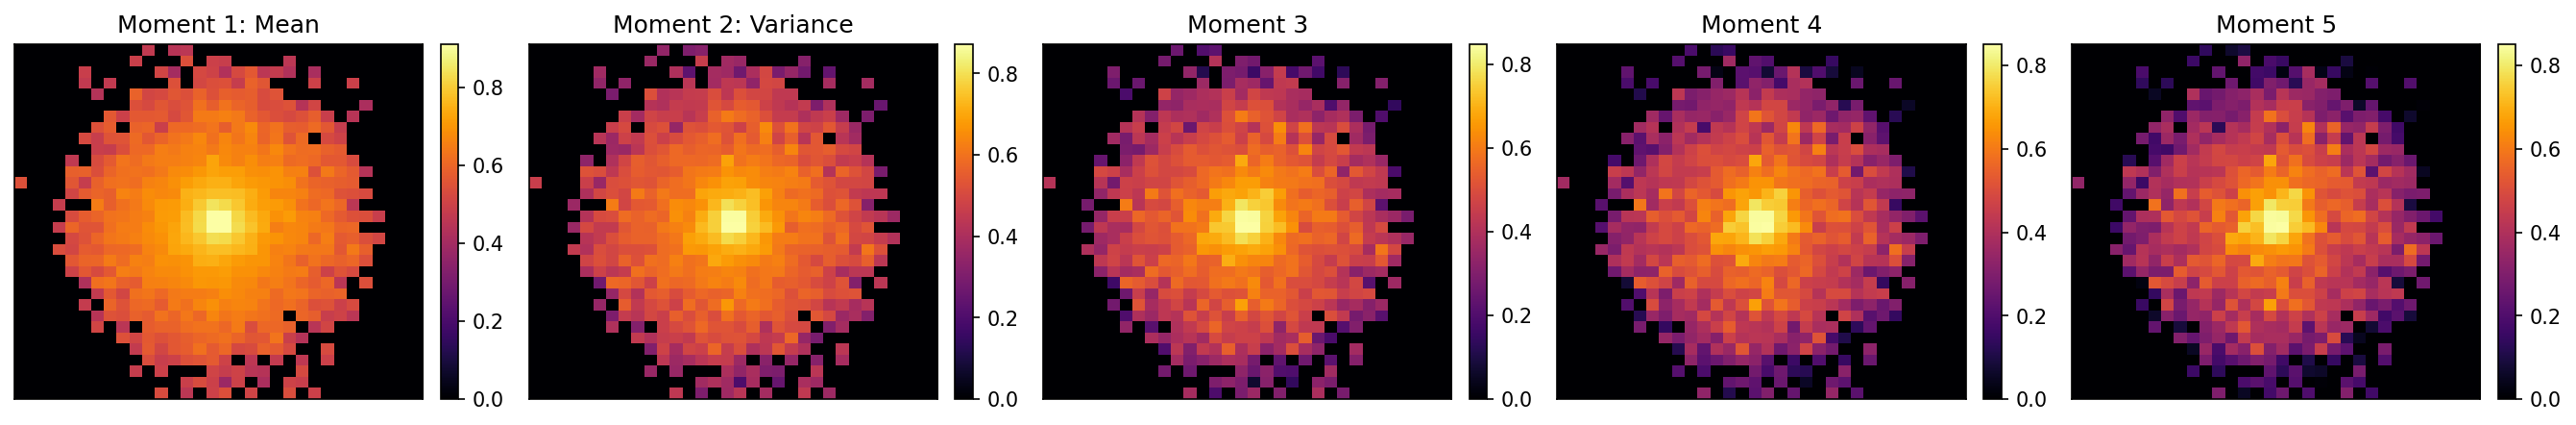

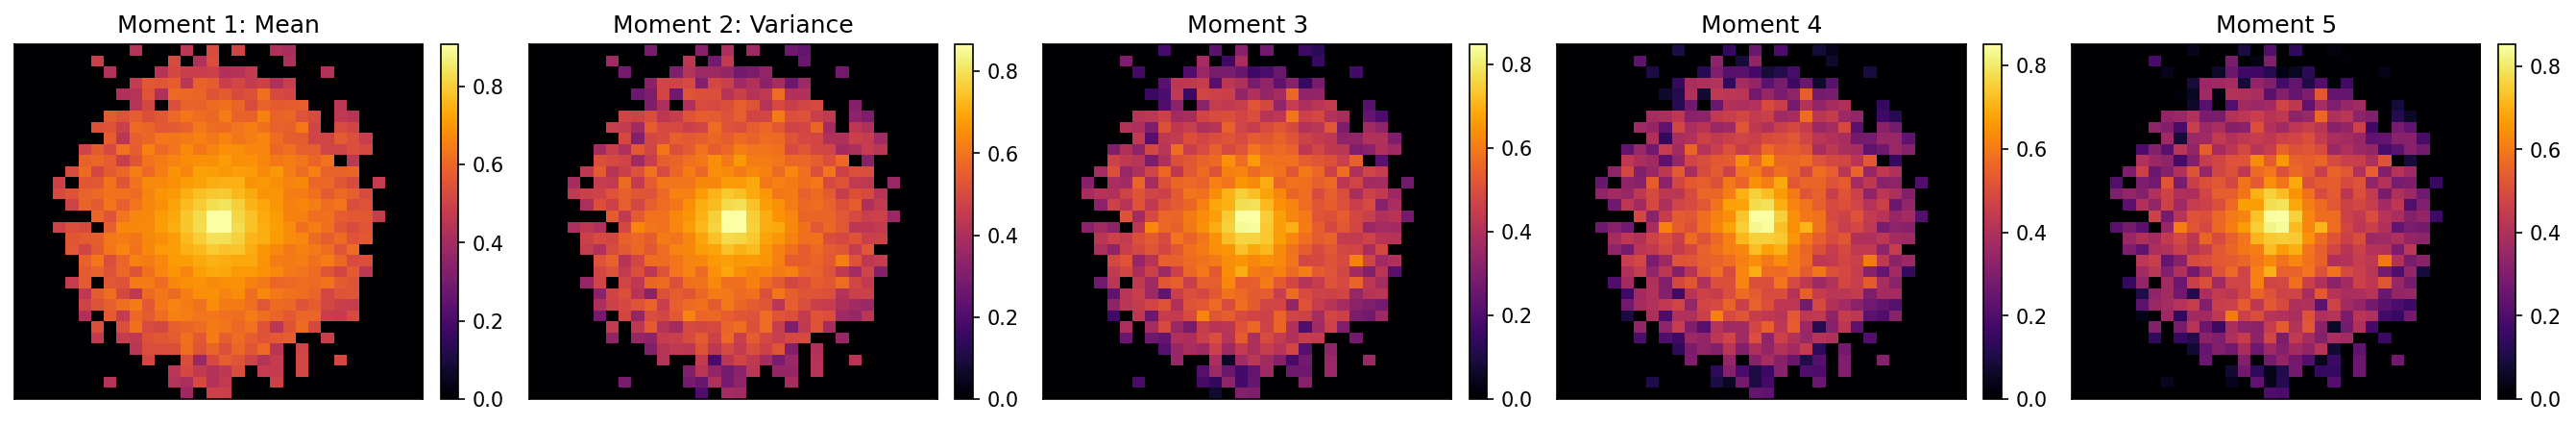

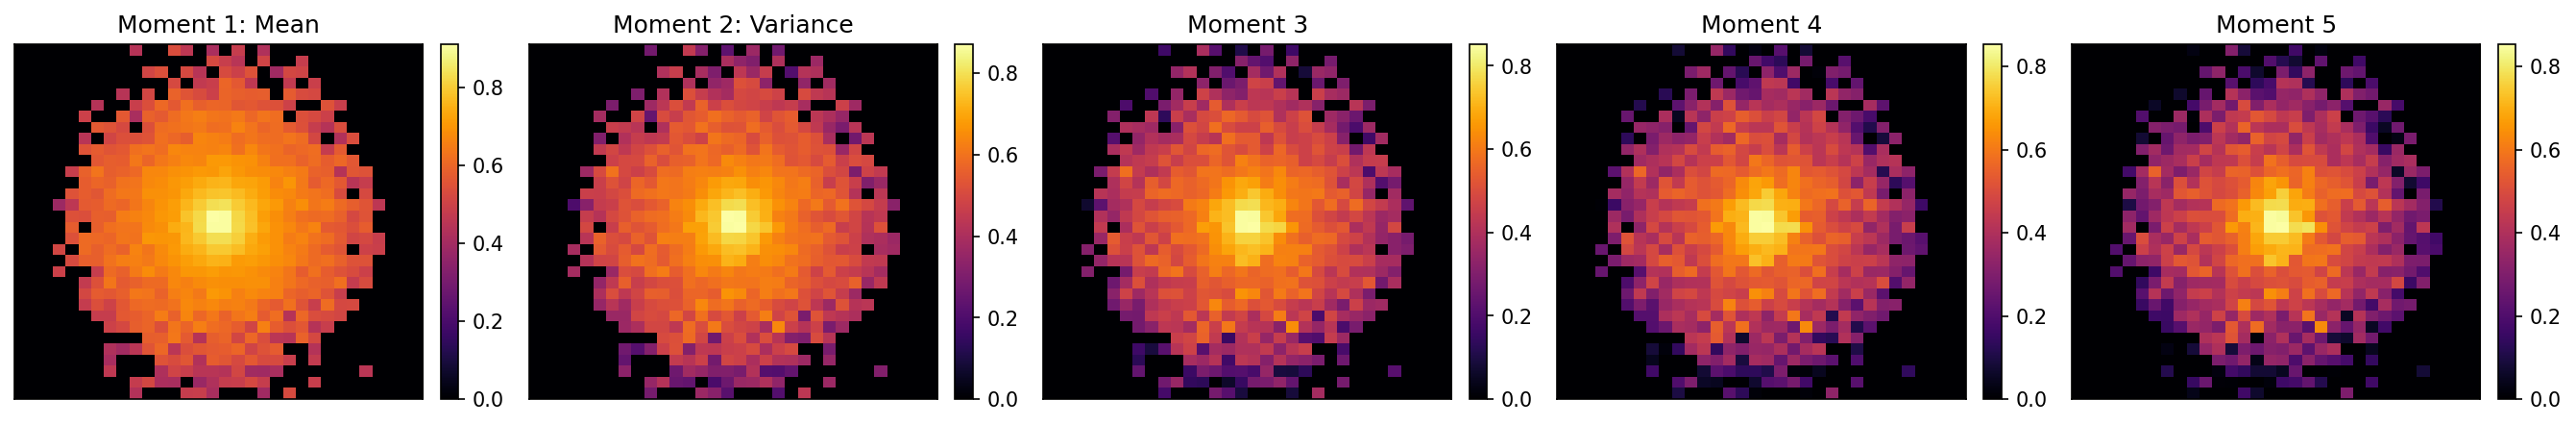

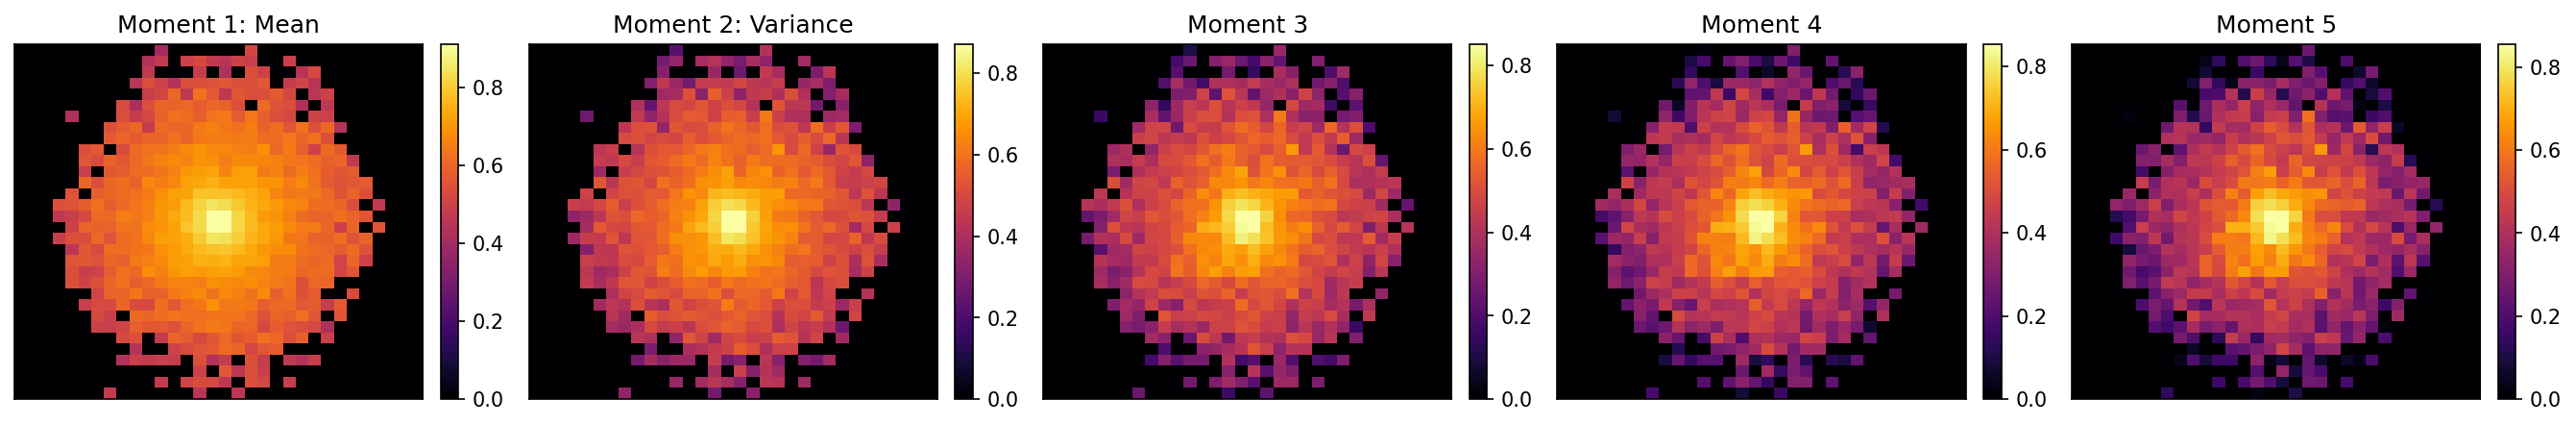

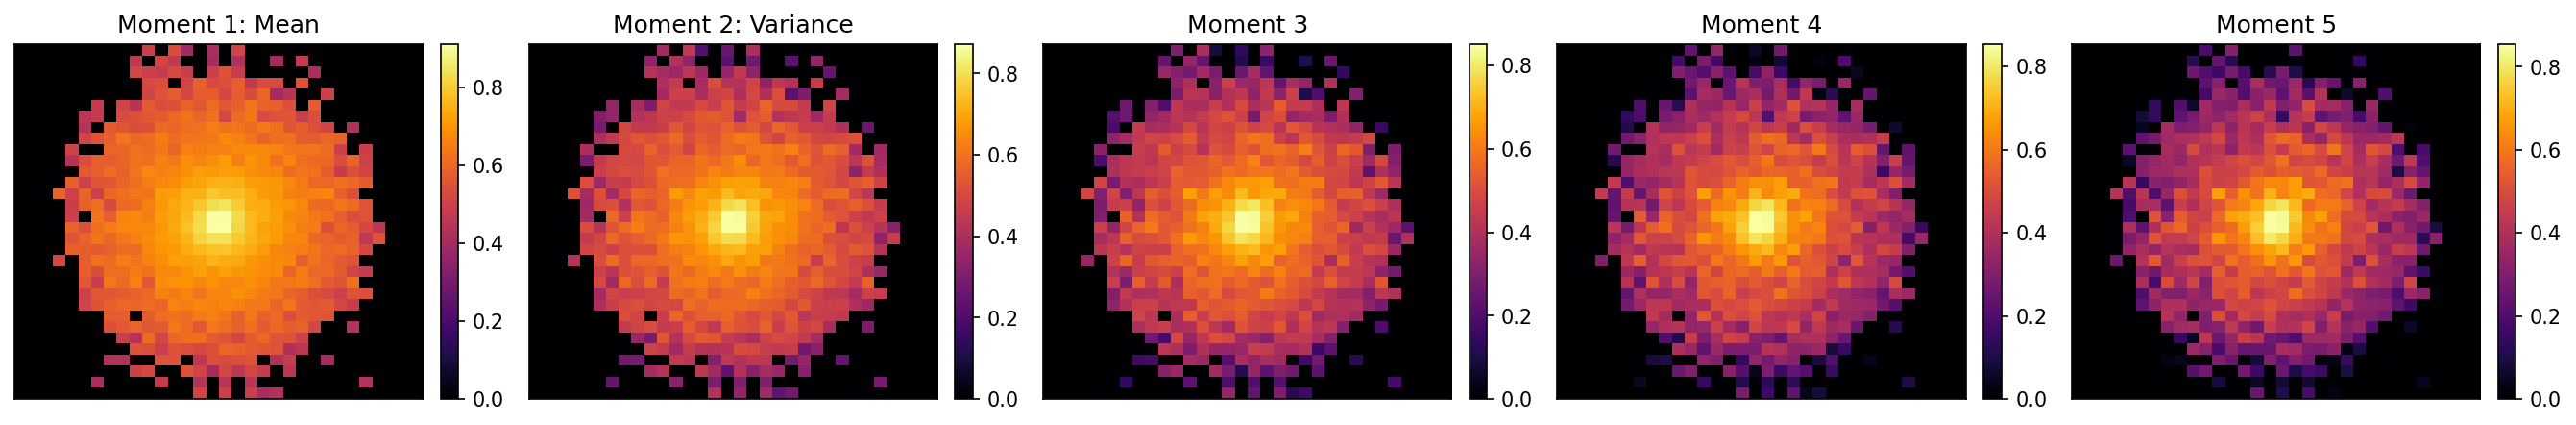

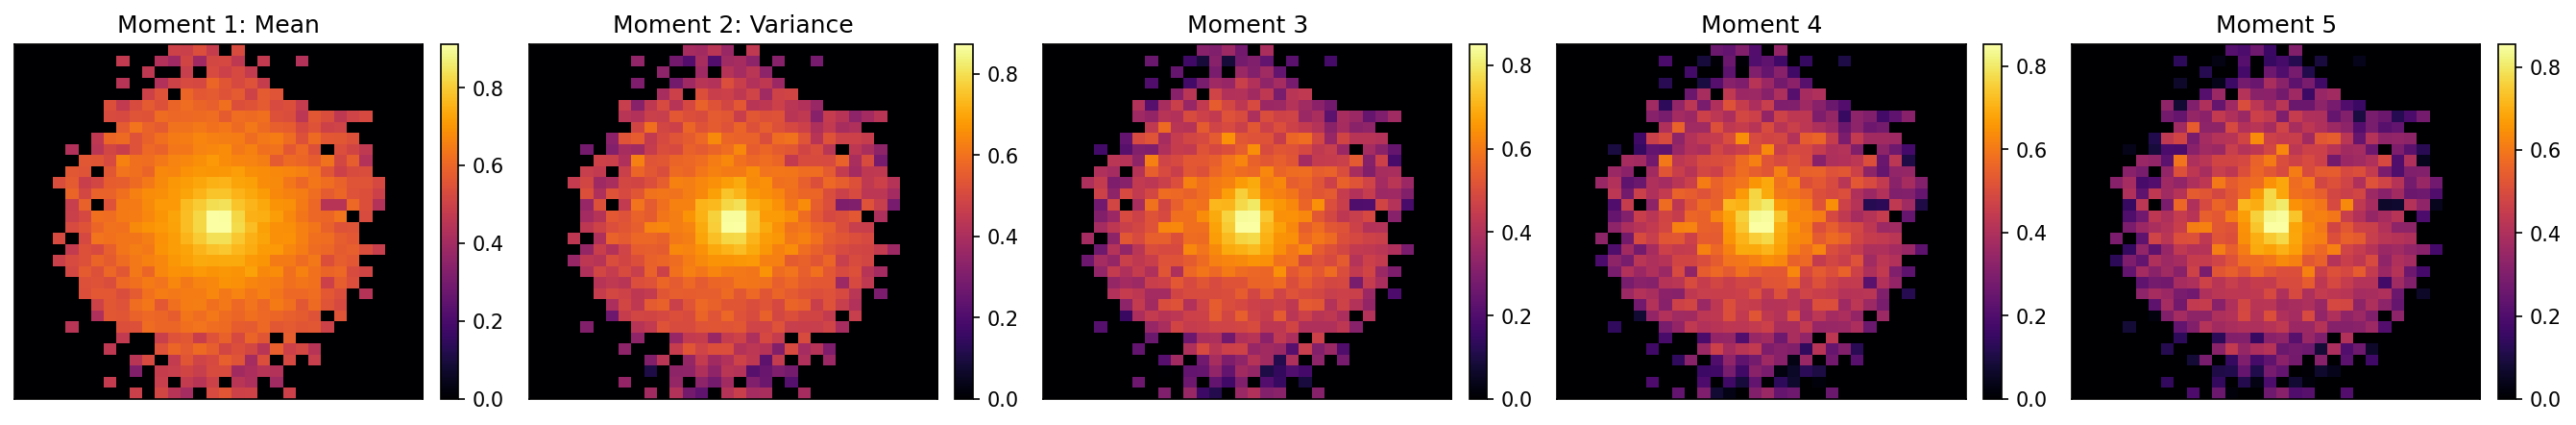

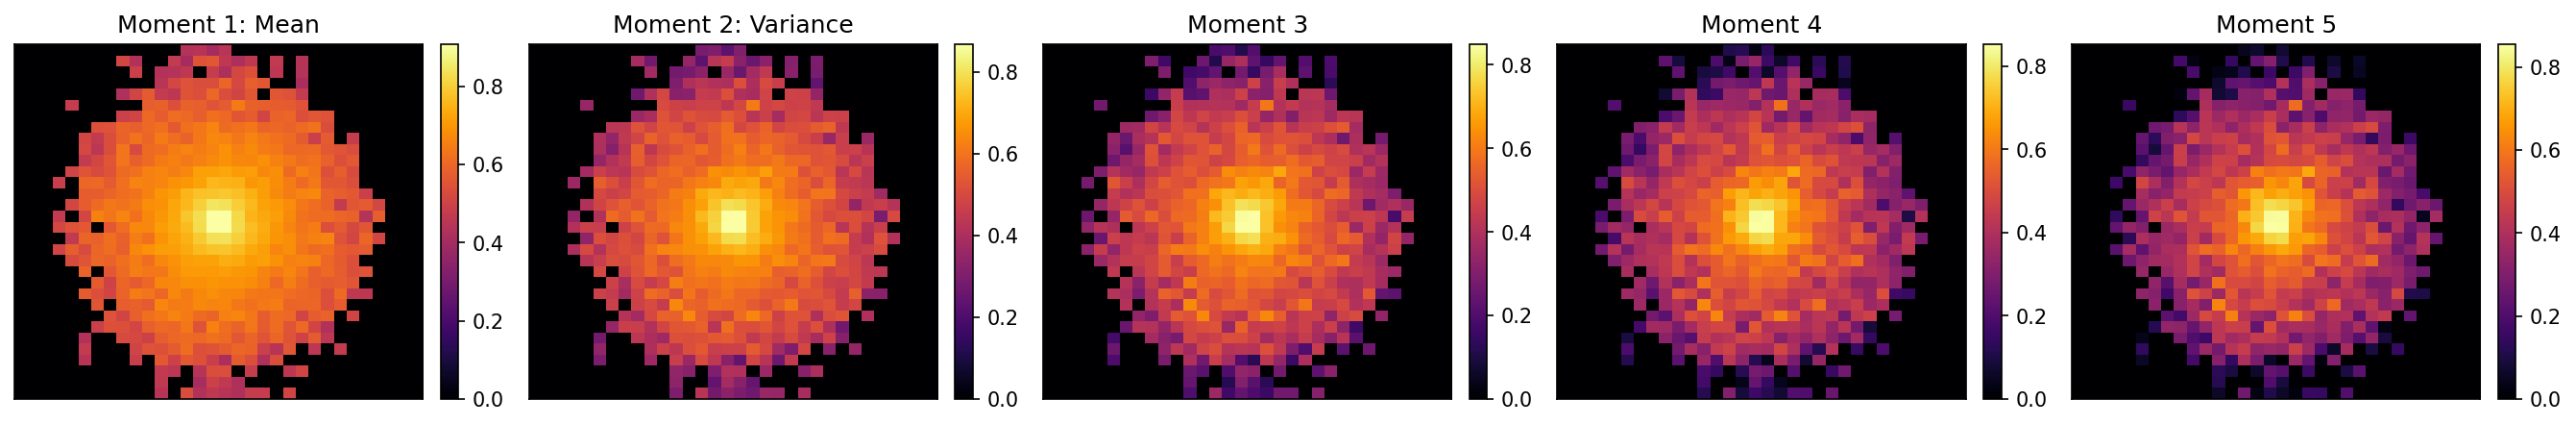

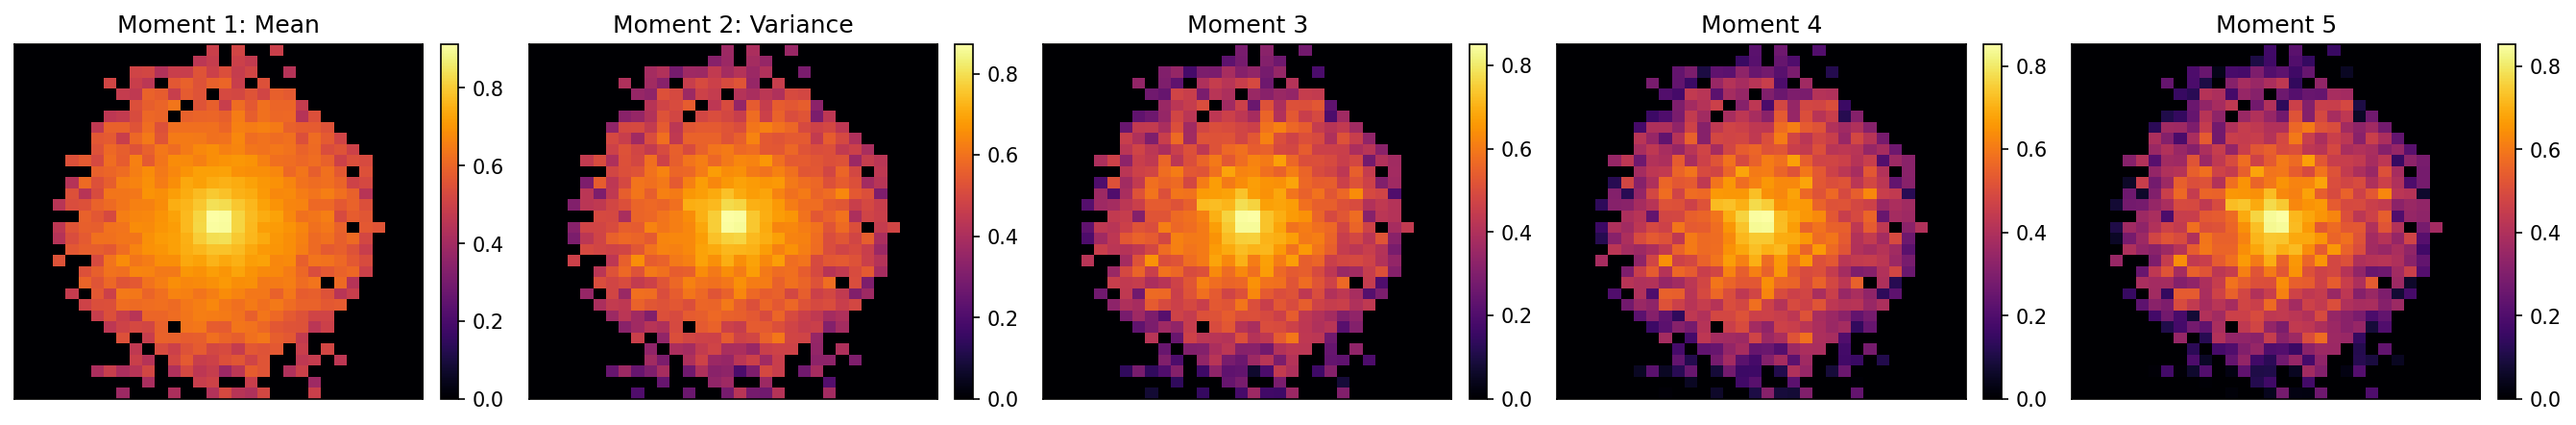

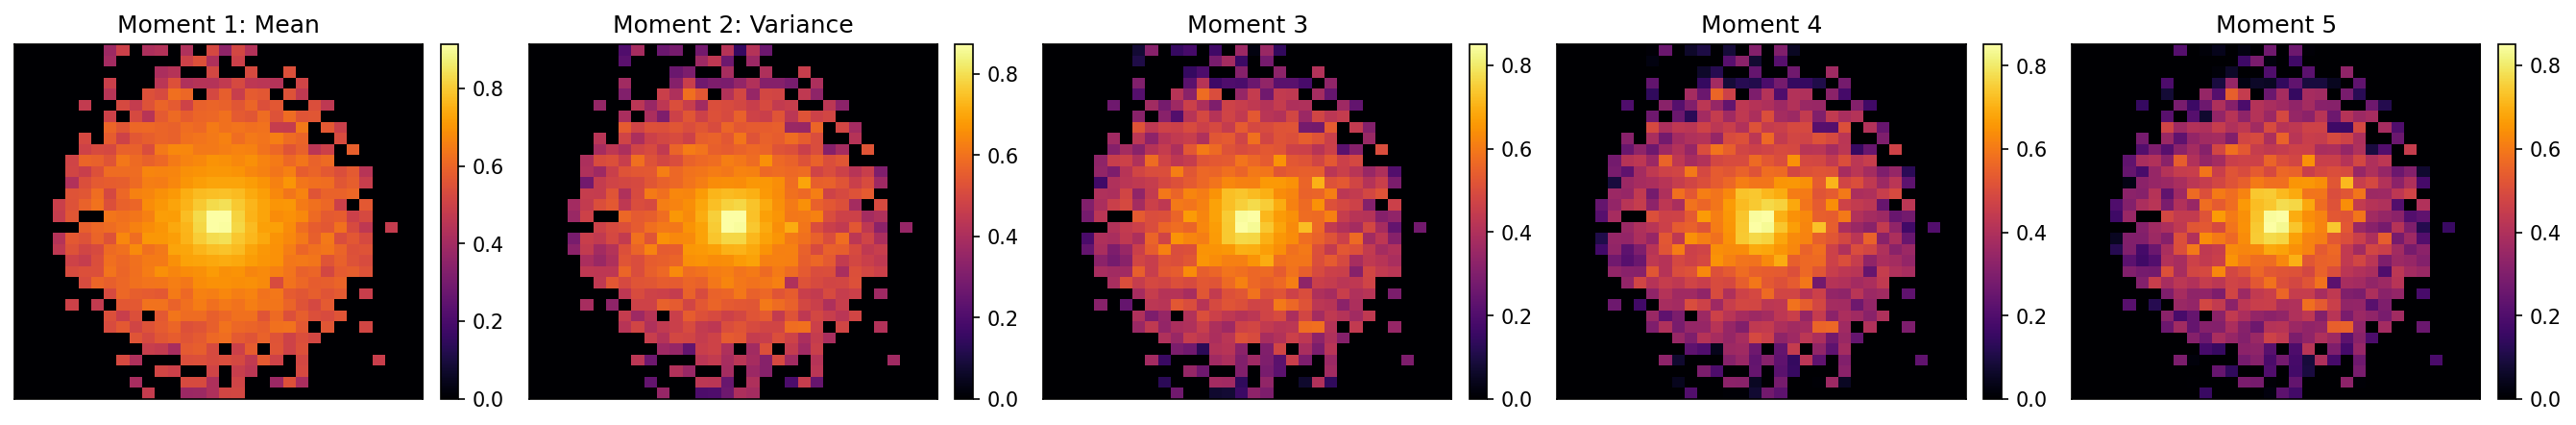

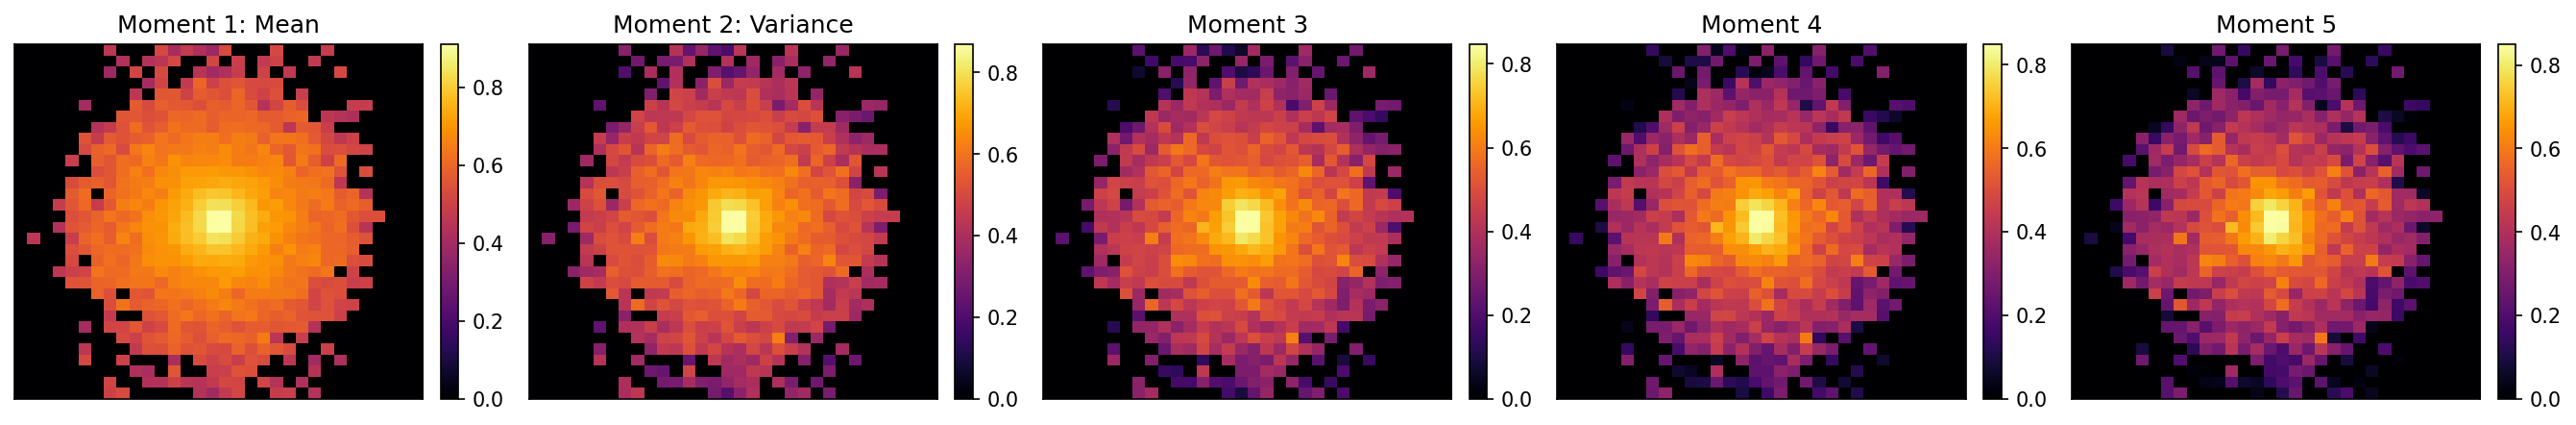

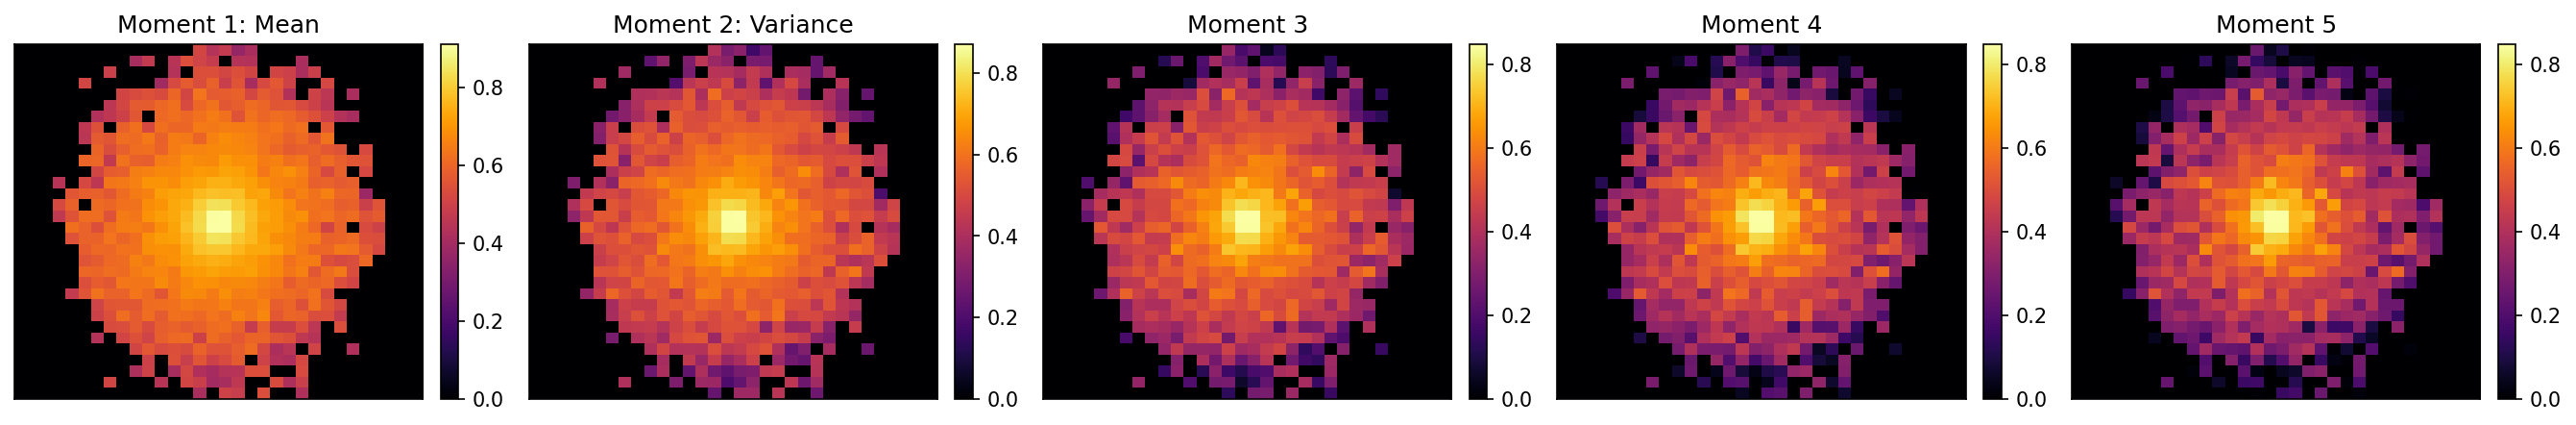

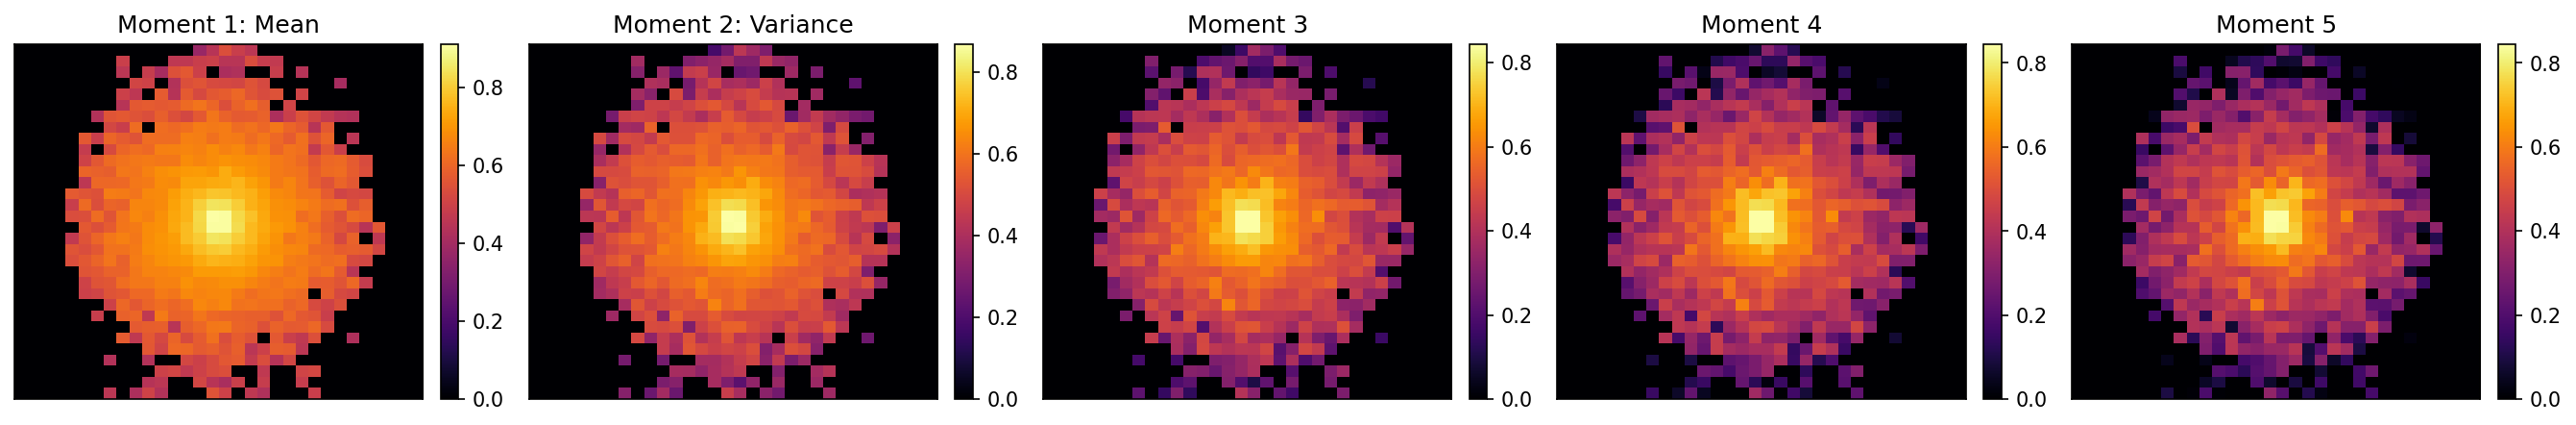

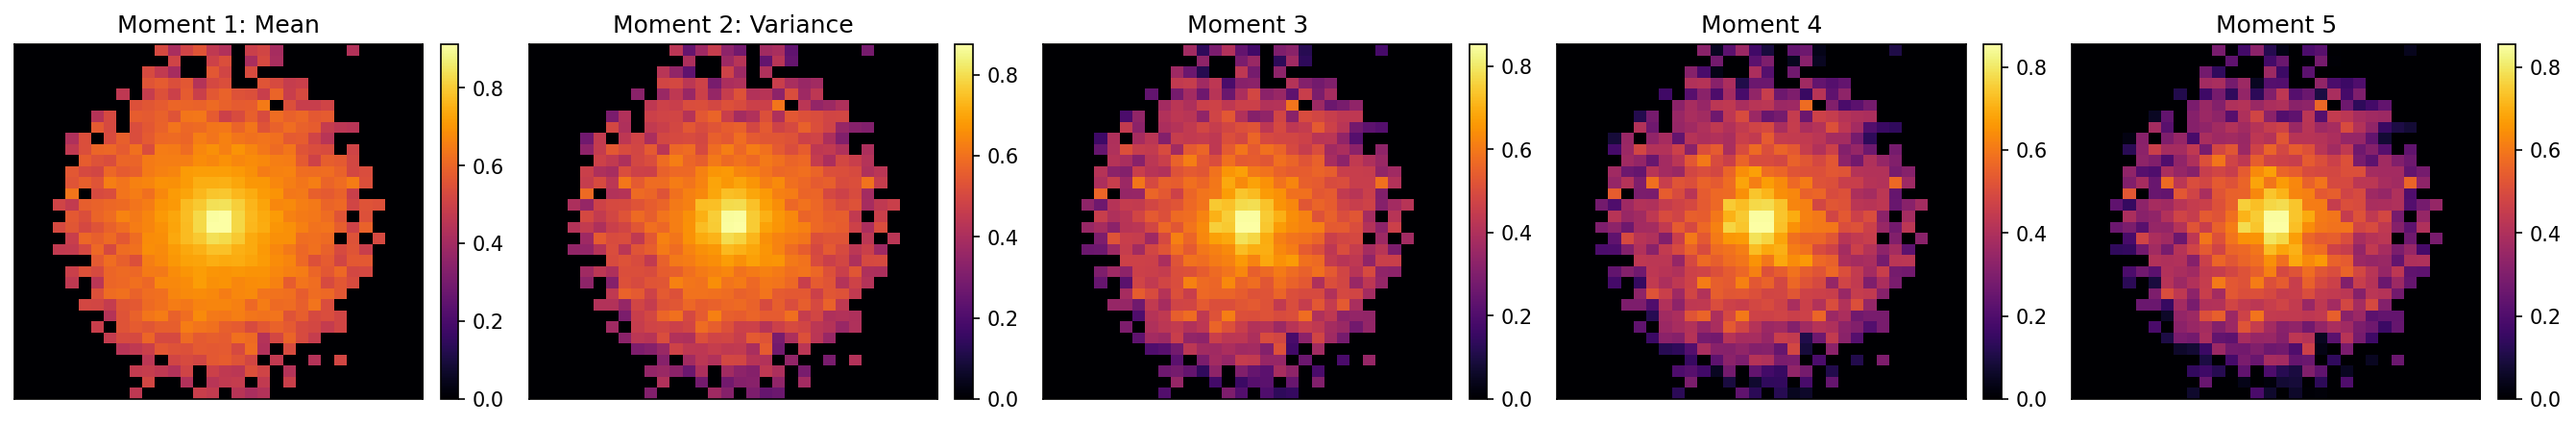

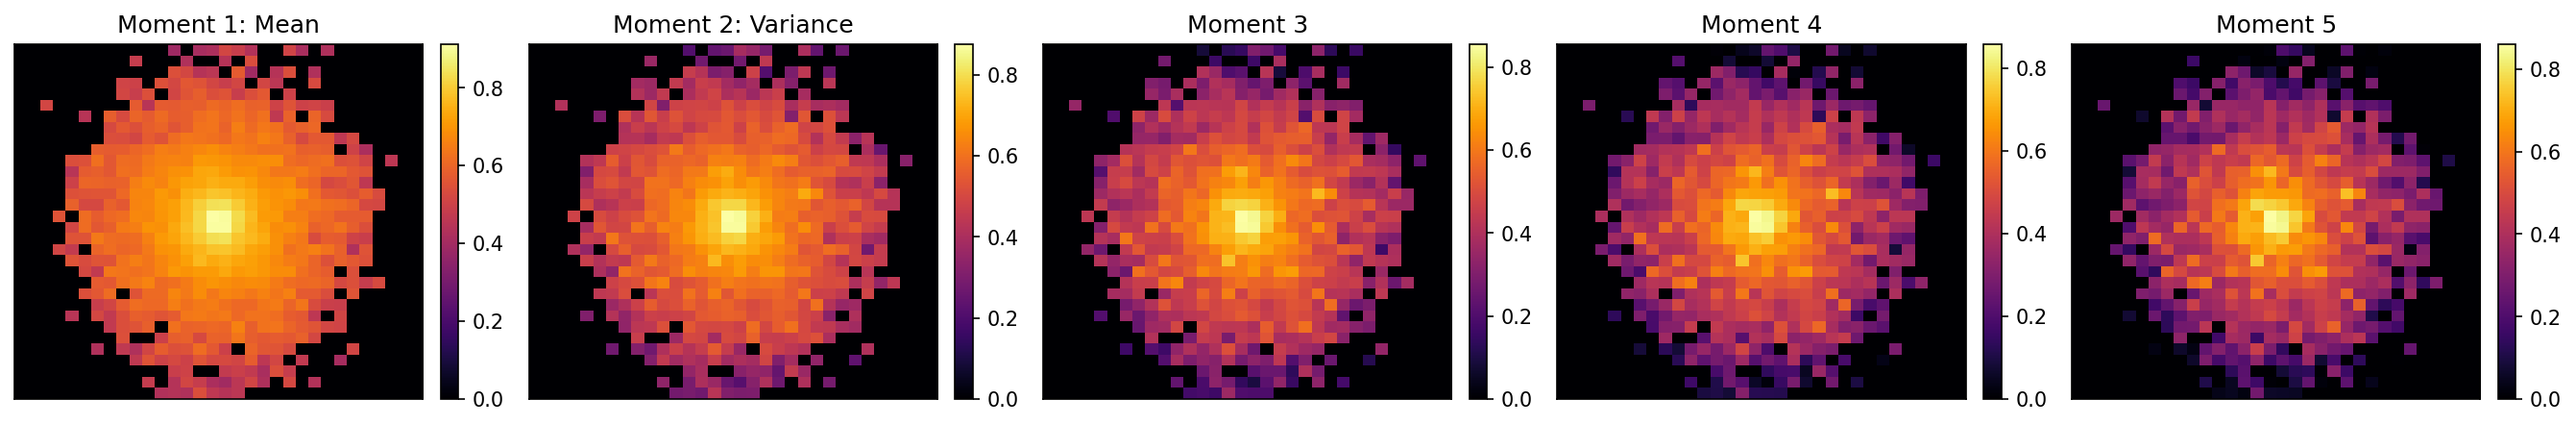

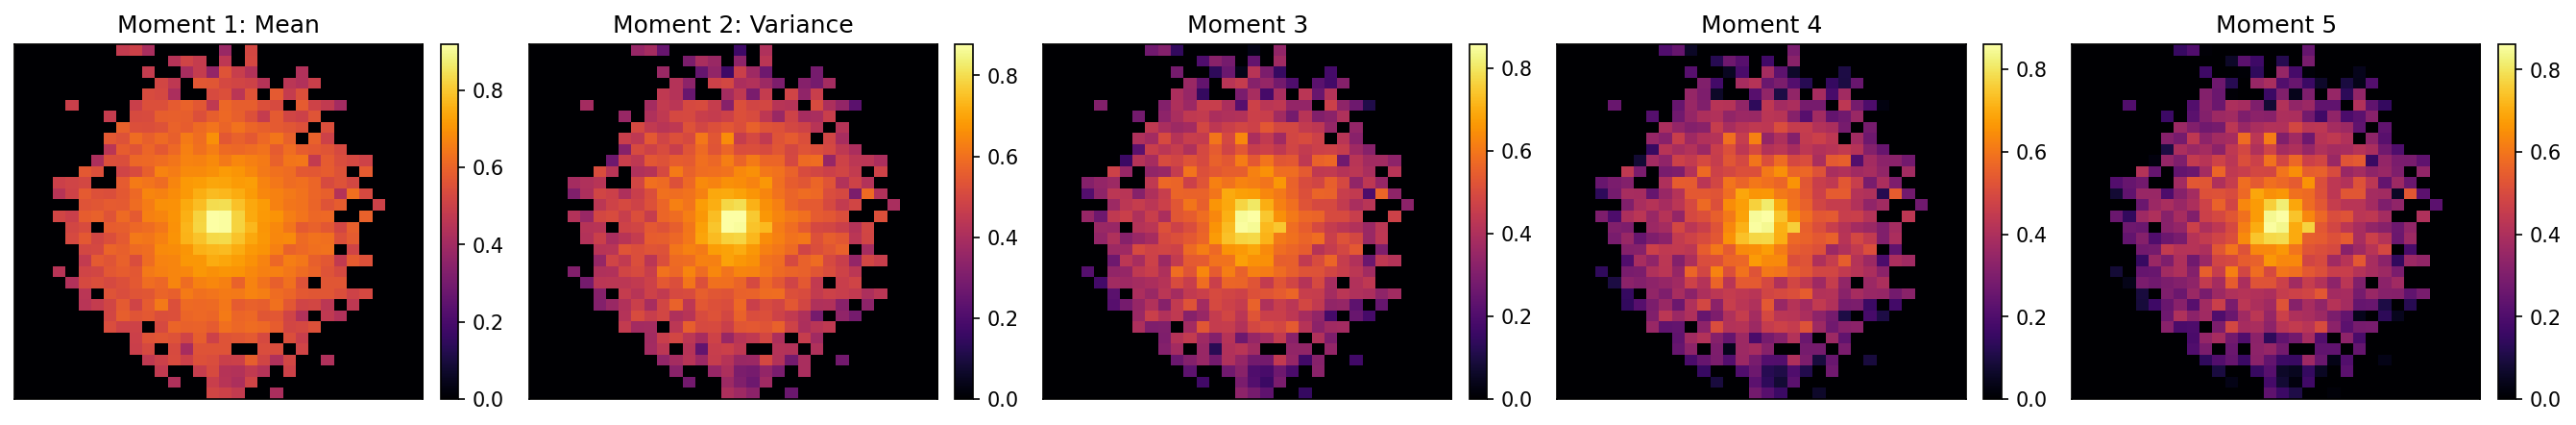

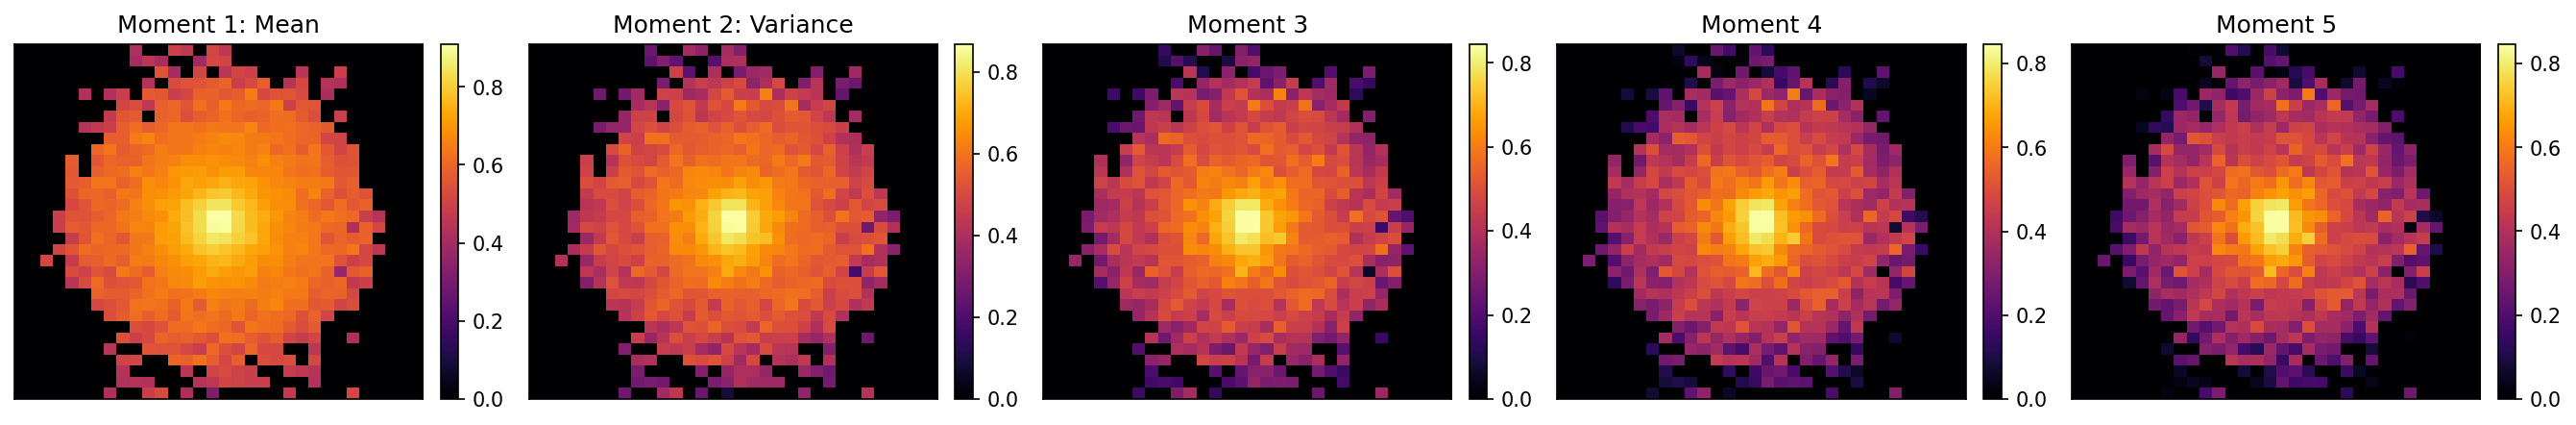

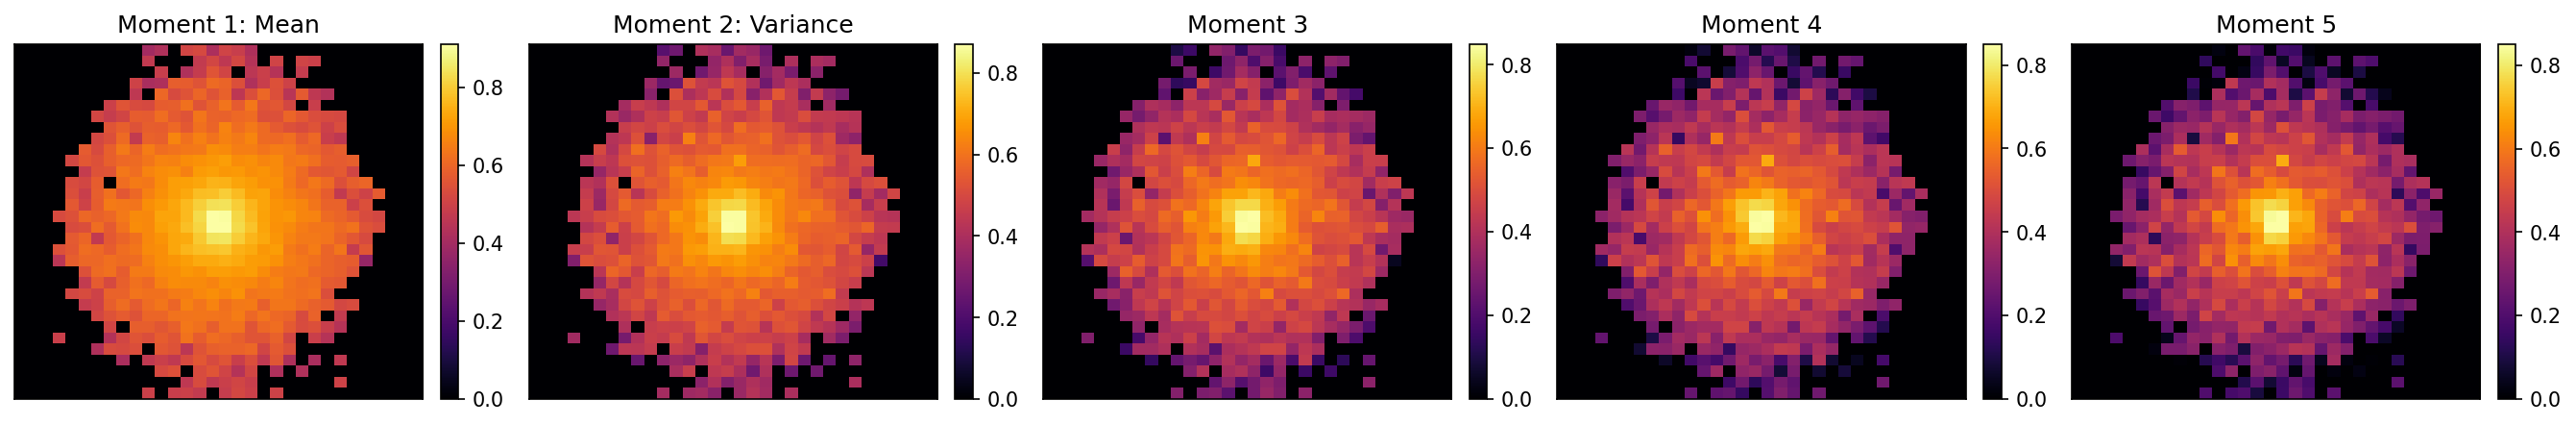

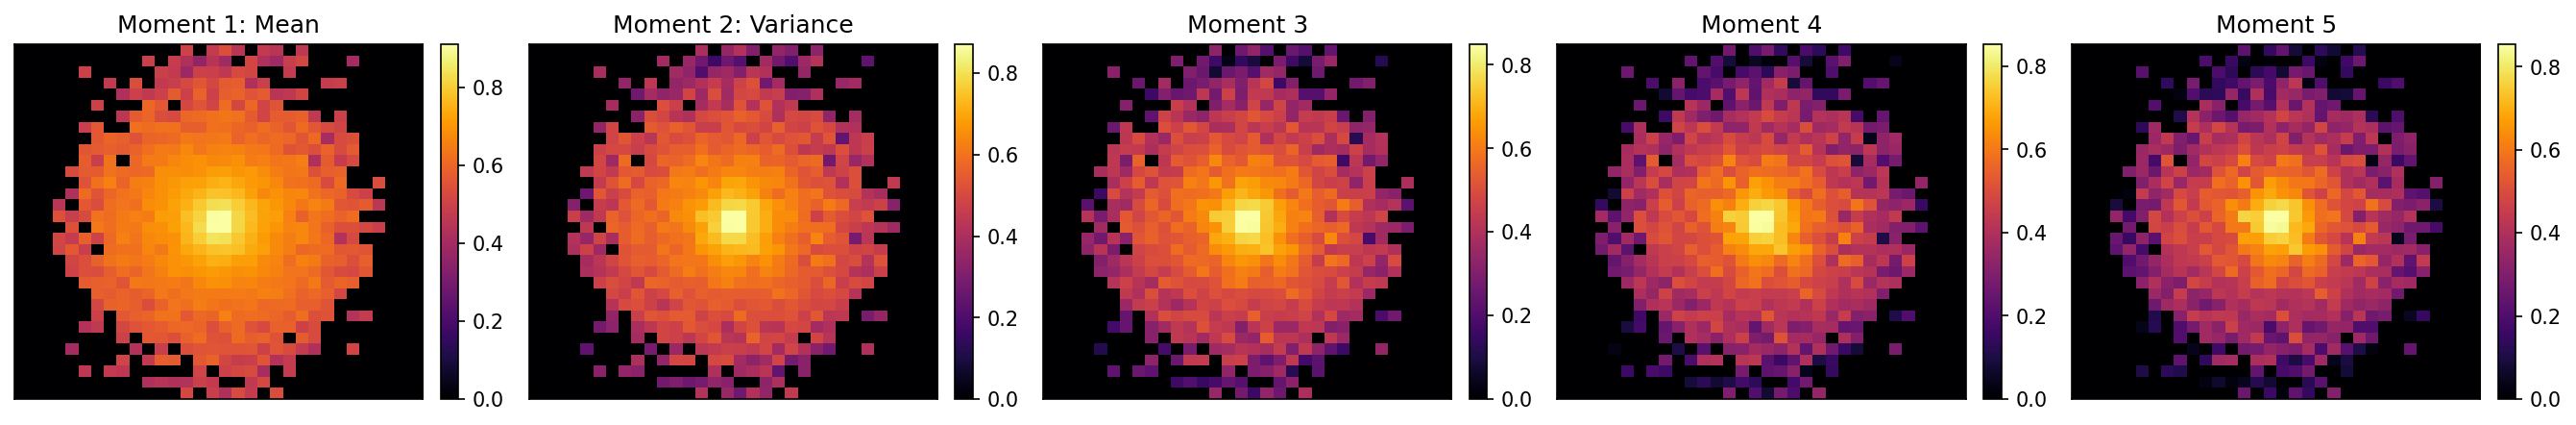

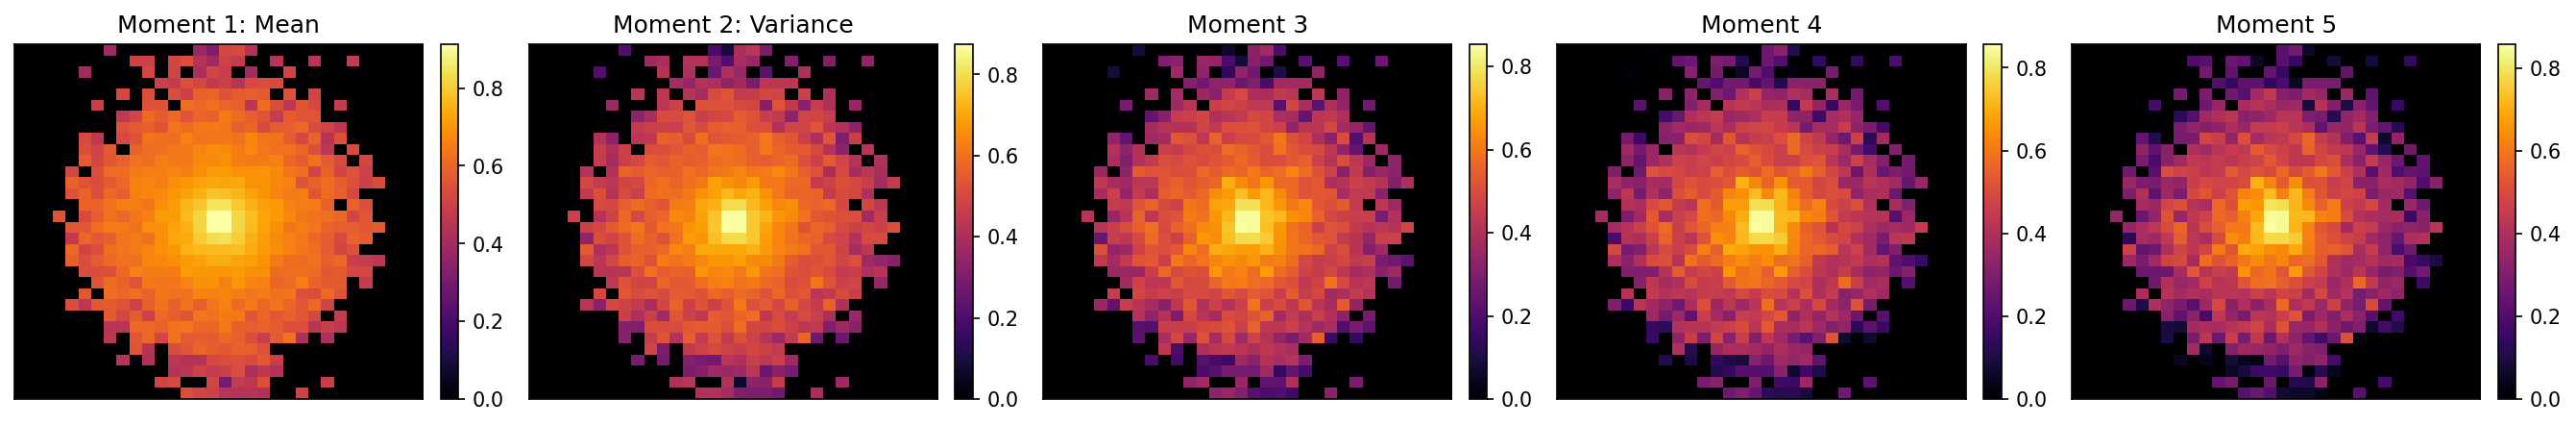

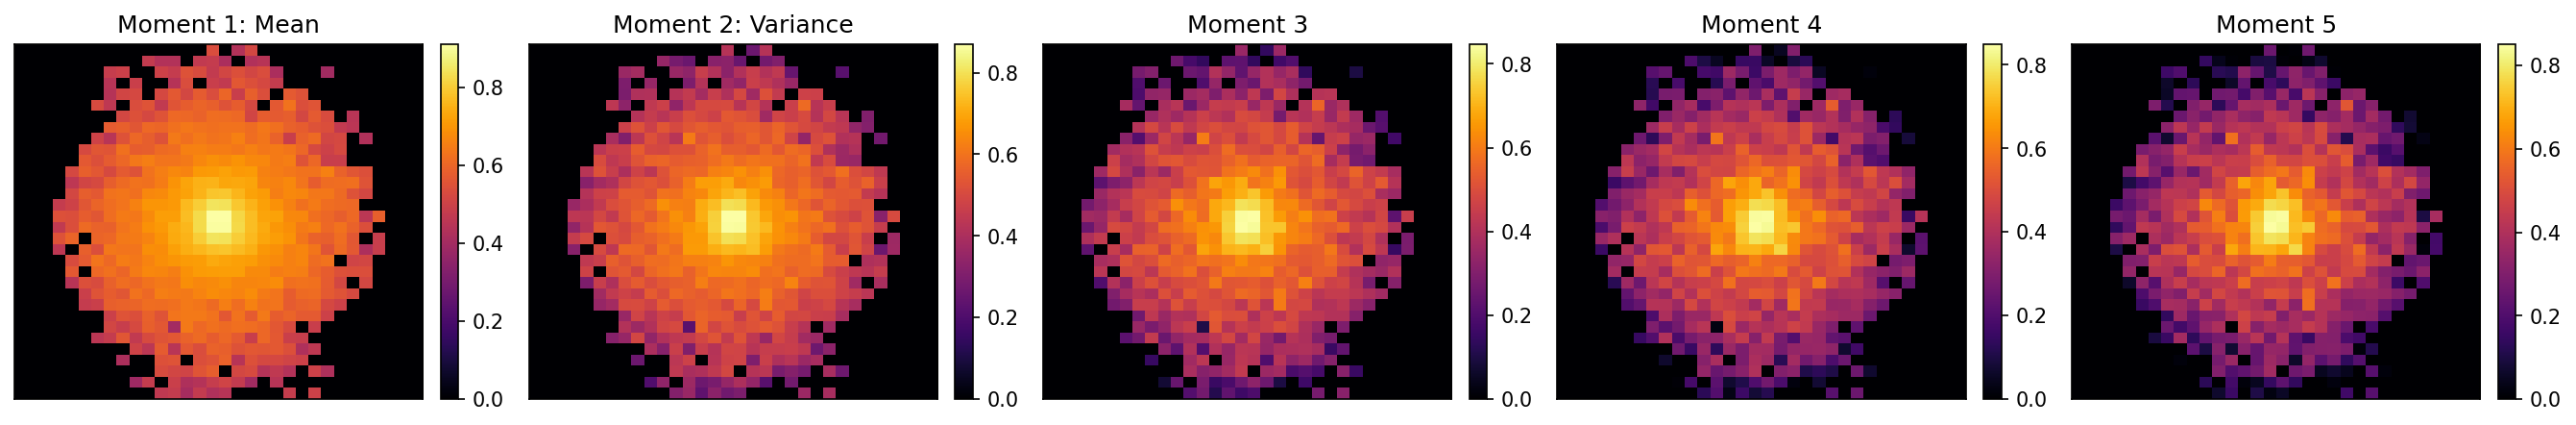

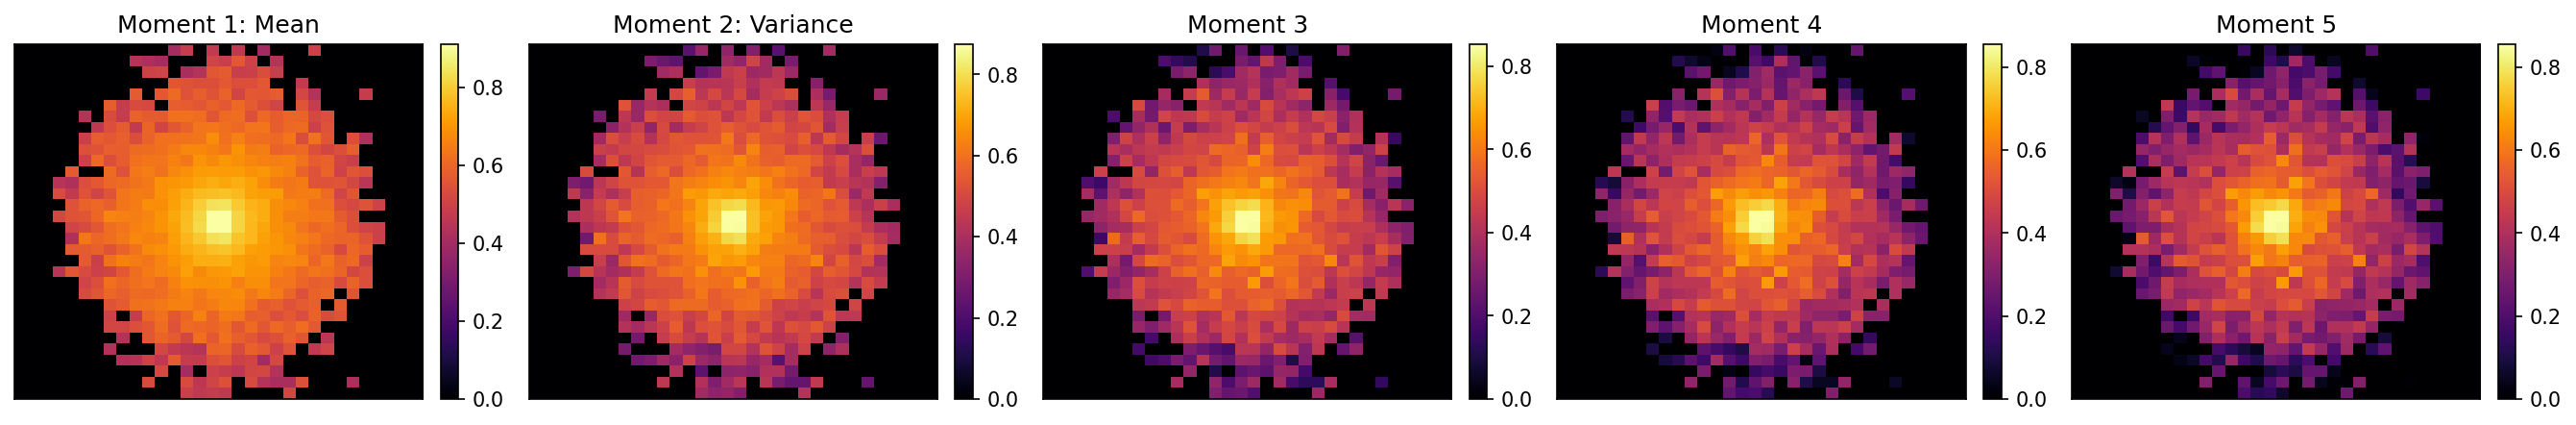

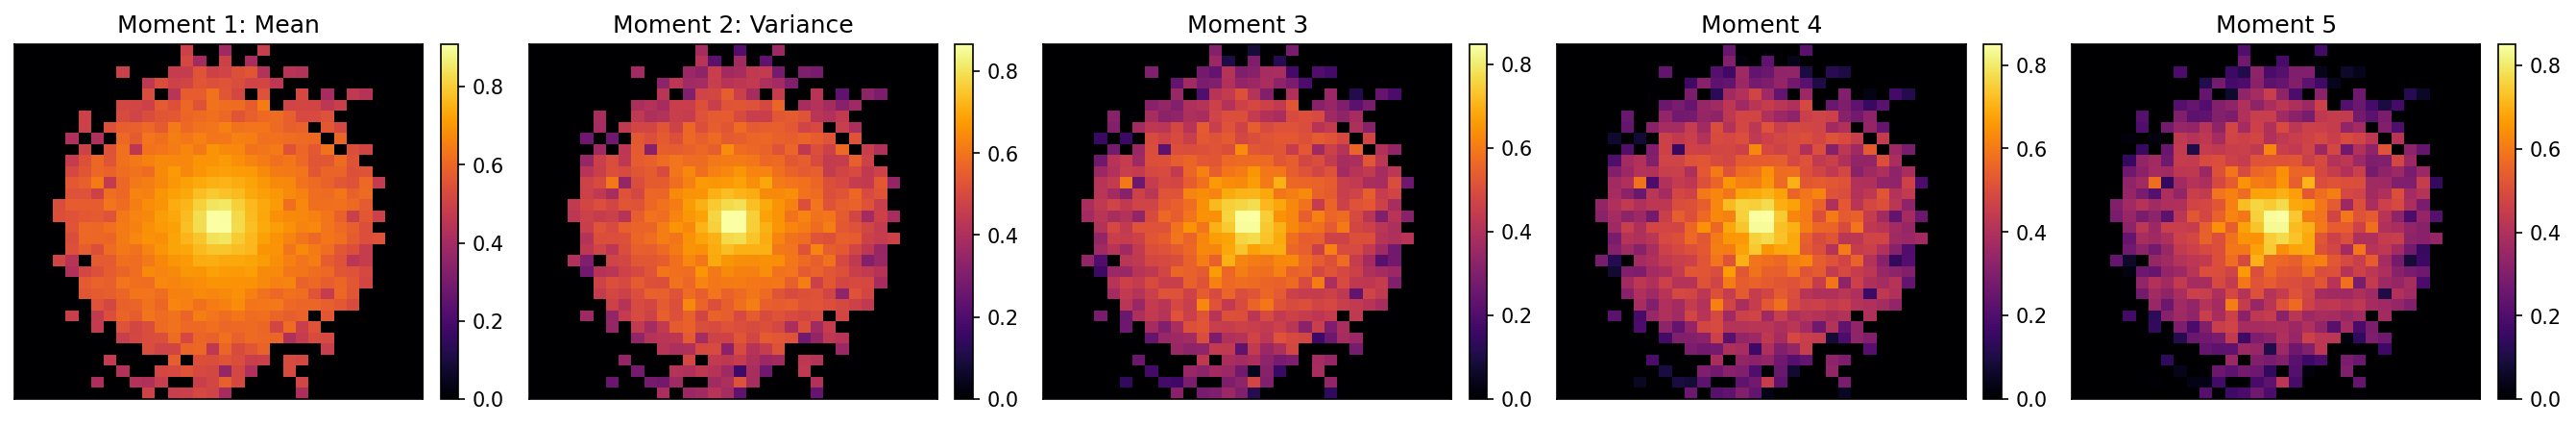

In [20]:
def visualize_moments(moments, titles = [
        "Moment 1: Mean",
        "Moment 2: Variance",
        "Moment 3",
        "Moment 4",
        "Moment 5"
    ]):
    

    fig, axes = plt.subplots(1, 5, figsize=(18, 3), dpi=150)

    for i in range(5):
        ax = axes[i]
        im = ax.imshow(moments[i].T, origin="lower", cmap="inferno", aspect="auto")
        ax.set_title(titles[i])
        ax.set_xticks([])
        ax.set_yticks([])
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

for idx, sample_arr in enumerate(config_sample_arr):
    # print(f"Visualizing config {idx}: {config_csvs[idx].name}")
    visualize_moments(sample_arr)
    # if idx == 0:  # Only visualize the first config for now
    #     visualize_moments(sample_arr)
    # else:
    #     visualize_moments(sample_arr, titles=None)

